# 17 · Fonctions d'activation — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch17_activations/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 17.Q1 à 17.Q12, 17.R1 à 17.R3, 17.1, 17.2, 17.4, 17.5, 17.6, 17.8 | vérifier tes réponses courtes | 🧠 🔁 ✏️ ∂ 🧮 | ★ à ★★ | |
| A | 17.11 | Un MLP sans activation sur les lunes : quelle frontière ? | 🔮 | ★ | 15 |
|  | 17.12 | identity, step, relu, leaky_relu et leurs dérivées | 🔨 | ★ | 15 |
|  | 17.13 | Sigmoïde, tanh et softplus sans débordement | 🔨 | ★★ | 25 |
|  | 17.14 | ELU, SiLU, GELU et le registre get_activation | 🔨 | ★★ | 25 |
| B | 17.15 | Softmax et log_softmax stables (astuce log-sum-exp) | 🔨 | ★★ | 25 |
|  | 17.16 | La Jacobienne de la softmax en NumPy | 🔨 | ★★★ | 30 |
|  | 17.17 | Chasse au bug : nan, inf et mauvais axe | 🐛 | ★★ | 25 |
| C | 17.18 | Reproduire la galerie de la figure 17.22, dérivées comprises | 🎨 | ★★ | 25 |
|  | 17.19 | Softmax et température : prédire la distribution | 🔮 | ★★ | 15 |
|  | 17.20 | Quatre activations de scikit-learn sur les lunes et les spirales | 📦 | ★★ | 25 |
|  | 17.21 | Diagnostiquer la saturation sur des histogrammes de pré-activations | 📈 | ★★ | 20 |
| D | 17.22 | Une batterie de tests paramétrés pour toutes les activations | 🛠️ | ★★ | 25 |
|  | 17.23 | Produit des dérivées sur 10 couches : sigmoïde, tanh, ReLU, GELU | 🔬 | ★★★ | 45 |
|  | 17.24 | Défi spirales : au moins 97 % avec au plus 2 000 paramètres | 🏆 | ★★★ | 60 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.13 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Voir qu'un réseau sans activation ne vaut qu'une couche, et ce qu'une ReLU y change.
- Écrire et vérifier contre SciPy et PyTorch les fonctions de `mylearn.nn.activations` : dix activations et leurs dérivées, `get_activation`, `softmax`, `log_softmax` et `softmax_derivative`, sans aucun débordement.
- Comparer les activations : saturation, température, choix pour un problème donné, gradients à travers dix couches.
- Tester toute une famille de fonctions avec des tests paramétrés et des tests de propriétés.

**Rappel express.** $\mathrm{ReLU}(z) = \max(0, z)$, $\mathrm{ReLU}'(0) = 0$ (PyTorch) ; $\sigma(z) = 1/(1 + e^{-z})$, $\sigma' = \sigma(1 - \sigma)$ ; $\tanh' = 1 - \tanh^2$ ; $\mathrm{softplus}(z) = \log(1 + e^z)$, $\mathrm{softplus}' = \sigma$ ; $\mathrm{ELU}(z) = \alpha(e^z - 1)$ pour $z \le 0$ ; $\mathrm{SiLU}(z) = z\,\sigma(z)$ ; $\mathrm{GELU}(z) = z\,\Phi(z)$, $\Phi(z) = \frac{1}{2}(1 + \mathrm{erf}(z/\sqrt{2}))$ ; $p_i = e^{z_i}/\sum_j e^{z_j}$, $\partial p_i/\partial z_j = p_i(\delta_{ij} - p_j)$ ; $\log\sum_j e^{z_j} = m + \log\sum_j e^{z_j - m}$. En NumPy : `np.exp(-np.abs(z))`, `np.log1p`, `np.expm1`, `np.where` (qui calcule les deux branches), `z.max(axis=-1, keepdims=True)`, `np.vectorize(math.erf)` ; en SciPy : `special.expit`, `special.softmax`, `special.log_softmax`, `special.erf`.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 17.1, 17.2, 17.5 et 17.6, ∂ 17.4 et 🧮 17.8)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; plusieurs choix ou une suite de codes : les caractères collés, dans l'ordre demandé (`"XYZ"`) ; une forme NumPy : entre guillemets (`"(5, 7)"`) ; plusieurs nombres : une liste (`[4, 7]`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », les preuves ∂ 17.3 et 17.7, les démonstrations de ∂ 17.4, la réflexion (🗣️ 17.9, 📄 17.10) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math

import numpy as np
from scipy import special


def sigma(z):
    return special.expit(z)


def dsigma(z):
    return special.expit(z) * special.expit(-z)


def Phi(z):
    return 0.5 * (1.0 + special.erf(np.asarray(z, dtype=float) / math.sqrt(2.0)))


def softmax(z):
    return special.softmax(np.asarray(z, dtype=float))


# 17.1: the 3-2-2-1 network without activation
W1_171 = np.array([[1.0, -2.0], [0.0, 1.0], [3.0, 1.0]])
B1_171 = np.array([1.0, -1.0])
W2_171 = np.array([[2.0, 1.0], [-1.0, 3.0]])
B2_171 = np.array([0.0, 2.0])
W3_171 = np.array([[1.0], [-2.0]])
B3_171 = 0.5
X_171 = np.array([1.0, 2.0, -1.0])
W_EQ_171 = (W1_171 @ W2_171 @ W3_171).ravel()
B_EQ_171 = float(((B1_171 @ W2_171 + B2_171) @ W3_171).item() + B3_171)


def out_171(x, f=lambda z: z):
    h = f(x @ W1_171 + B1_171)
    g = f(h @ W2_171 + B2_171)
    return float((g @ W3_171).item() + B3_171)


# 17.2: nine activations at two points (Phi rounded as in the statement)
PHI_172 = {-1.0: 0.1587, 1.5: 0.9332}


def nine_172(z):
    return [max(0.0, z), z if z > 0 else 0.1 * z, max(z, -0.5), math.log1p(math.exp(z)),
            z if z > 0 else math.expm1(z), float(sigma(z)), math.tanh(z), z * float(sigma(z)), z * PHI_172[z]]


# 17.5: the maxout of three lines
LINES_175 = [(-2.0, -1.0), (0.5, -0.5), (3.0, -4.0)]


def maxout_175(z):
    return max(a * z + b for a, b in LINES_175)


# 17.6: the six scores of figure 17.24
Z_176 = np.array([0.3, 0.1, 0.8, 0.4, 0.2, 0.6])          # A to F
P_176 = softmax(Z_176)

# 17.8: a 1024 -> 1024 layer on a batch of 256
MULTS_178 = 256 * 1024 * 1024
VALUES_178 = 256 * 1024
BYTES_178 = VALUES_178 * 4 * 2

**17.Q1 — À quoi sert la fonction d'activation ?**

In [3]:
wb.record("17.Q1a", 4 * 2 + 2, mistakes={"c'est le compte du MLP 4-8-8-2 de départ ; la couche unique relie directement 4 entrées à 2 sorties": 4 * 8 + 8 + 8 * 8 + 8 + 8 * 2 + 2,
          "une couche dense a aussi un biais par neurone de sortie": 8,
          "tu as compté la première couche du réseau de départ ; la couche unique relie les entrées aux sorties": 40,
          "la couche unique relie les 4 entrées aux 2 sorties : combien de poids, combien de biais ?": 6})
wb.record("17.Q1b", False, mistakes={"une activation affine se fond-elle dans la couche suivante ? Compose deux applications affines": True})
wb.record("17.Q1c", "C", mistakes={"les poids multiplient les entrées brutes : l'activation vient-elle avant ?": "A",
          "le neurone additionne d'abord tous ses produits, et son biais": "B",
          "chaque couche cachée a son activation, pas seulement la sortie": "D"})
wb.record("17.Q1d", False, mistakes={"sans activation entre elles, les trois couches cachées se composent-elles en une seule application affine ?": True})

WB_ANSWER {"hash": "96f518093b9d7e7ab5be5ec15512bfa121914e85ef52bcb5966bcb1c87626821", "id": "17.Q1a", "kind": "int", "magnitude": 1, "mistakes": {"09e2fc54c6dc3c7165e3cef6593613f6493f9f69574dcaeeaa2b787a2378407a": "la couche unique relie les 4 entrées aux 2 sorties : combien de poids, combien de biais ?", "1c0ce84c67712cff3e9befaa420f4174feb1f2239ba3a30d3513938fb961840d": "une couche dense a aussi un biais par neurone de sortie", "496149782b2f341dc65b0f92277172b6c5745fb13f05f7426b1724ee858aa251": "c'est le compte du MLP 4-8-8-2 de départ ; la couche unique relie directement 4 entrées à 2 sorties", "f77910af40bbd42a354755c9f65ddbd3fb23800e1a71536106a598752cb8a9d2": "tu as compté la première couche du réseau de départ ; la couche unique relie les entrées aux sorties"}, "sign": 1}
📝 Ex 17.Q1a : réponse enregistrée (int).
WB_ANSWER {"hash": "dcd3de76256b14f09dd7cde05520821ee340ffb44f85646c714b0286c37eb46e", "id": "17.Q1b", "kind": "bool", "mistakes": {"6d36e239f0adabd287376a5bff536f08d50c

**17.Q2 — Un nombre en entrée, un nombre en sortie : la forme d'une activation**

In [4]:
wb.record("17.Q2a", "(32, 10)", mistakes={"une activation élément par élément agit sur chaque case : la forme change-t-elle ?": "(32,)",
          "chaque case reste à sa place : une ligne par exemple, une colonne par neurone": "(10, 32)",
          "aucune réduction : une valeur de sortie par valeur d'entrée": "(10,)"})
wb.record("17.Q2b", True, mistakes={"relis le §17.2.1 : que fait-on en pratique, neurone par neurone ou couche par couche ?": False})
wb.record("17.Q2c", "A", mistakes={"un noyau est une notion du ch. 13 (SVM)": "B", "un logit est un score de sortie, avant la softmax": "C",
          "une fonction de répartition est une notion de probabilités (GELU en utilise une)": "D"})
wb.record("17.Q2d", False, mistakes={"élément par élément : de quoi dépend chaque case du résultat ?": True})

WB_ANSWER {"hash": "a32200bdc0999722e748d0bfb95d538e5f4f612d037ab5098f26f73bb10d9e91", "id": "17.Q2a", "kind": "str", "mistakes": {"6906084bfc2a555859bae83f8c4daa085713d8c1d0a235ba46c813942322dbfe": "chaque case reste à sa place : une ligne par exemple, une colonne par neurone", "a1ef9d3af93e8c466e6fb72107bde61a34507950eeb1849d141642b15e38c264": "une activation élément par élément agit sur chaque case : la forme change-t-elle ?", "aa355d84e898d5f8338cec858c1954d5be64192be73cb0a42e69afa68596237b": "aucune réduction : une valeur de sortie par valeur d'entrée"}}
📝 Ex 17.Q2a : réponse enregistrée (str).
WB_ANSWER {"hash": "0e50037d6a5301f7dc0a115549a013b834f1a29f833cfd726ad3b01b1c05aac9", "id": "17.Q2b", "kind": "bool", "mistakes": {"2a028b8d63b68e52722cb7a4ab73d9e92fbe67ae19c0ea4d06ffb4c365222b78": "relis le §17.2.1 : que fait-on en pratique, neurone par neurone ou couche par couche ?"}}
📝 Ex 17.Q2b : réponse enregistrée (bool).
WB_ANSWER {"hash": "61f0a53d6a1eff144d19435f6ba9393786d0c9bd

**17.Q3 — Linéaire ou non linéaire ? Classer six courbes**

In [5]:
wb.record("17.Q3a", "LLNNNL", mistakes={"relis l'élément 2 : une droite qui ne passe pas par l'origine est-elle « linéaire » au sens du livre ?": "LNNNNL",
          "relis l'élément 6 : deux morceaux qui suivent la même formule forment-ils une seule droite ?": "LLNNNN",
          "relis l'élément 3 : un escalier est-il une seule droite ?": "LLLNNL",
          "relis l'élément 4 : la valeur absolue a-t-elle un coude ?": "LLNLNL",
          "relis l'élément 5 : ReLU a-t-elle un coude ?": "LLNNLL"})

WB_ANSWER {"hash": "671f8170e8dfdfdaa8a82967d631c151e03051e309b9f9783702516c7a1cbb83", "id": "17.Q3a", "kind": "str", "mistakes": {"1f4a5400e232fe644480948292cf39acc10f9018b8f372673de94382ff89d52a": "relis l'élément 3 : un escalier est-il une seule droite ?", "782ef0716ef517f694e48178c9d443dee2938671133990151f1fdc54b216e7be": "relis l'élément 5 : ReLU a-t-elle un coude ?", "8d1636c381d2fee095b5b394b89027f1ecae41f1028439287fa58b975d461072": "relis l'élément 6 : deux morceaux qui suivent la même formule forment-ils une seule droite ?", "f152adb3bf85d1392f9b8158517e3f3f26b730c3ff3ea594defaf1e40eec36be": "relis l'élément 4 : la valeur absolue a-t-elle un coude ?", "fbcbd2b4a02db88d10684cfbc67d03f136563b5929caba9665853fb96b9b3d67": "relis l'élément 2 : une droite qui ne passe pas par l'origine est-elle « linéaire » au sens du livre ?"}}
📝 Ex 17.Q3a : réponse enregistrée (str).


**17.Q4 — Pourquoi une activation doit-elle donner une seule valeur par entrée ?**

In [6]:
wb.record("17.Q4a", False, mistakes={"combien de points du cercle se trouvent au-dessus de z = 0 ?": True})
wb.record("17.Q4b", True, mistakes={"relis le §17.3.1 : une fonction doit-elle être continue, ou avoir une seule valeur par entrée ?": False})
wb.record("17.Q4c", "AD", mistakes={"une verticale coupe-t-elle la parabole couchée en un seul point ?": "ABD",
          "il en manque une : refais le test de la verticale sur chaque courbe": "A",
          "une verticale coupe-t-elle un cercle en un seul point ?": "ACD",
          "une droite verticale donne une infinité de valeurs pour z = 1": "ADE",
          "il en manque une : refais le test de la verticale pour chaque courbe": "D"})

WB_ANSWER {"hash": "f689d5a759d05317c056fe37a1bed5a45bb8ee5e86a3e5c6faf9084089eb2f0e", "id": "17.Q4a", "kind": "bool", "mistakes": {"60c4301614870b394efc329feeb443e5029c1312c5d54181199942a5983e6646": "combien de points du cercle se trouvent au-dessus de z = 0 ?"}}
📝 Ex 17.Q4a : réponse enregistrée (bool).
WB_ANSWER {"hash": "bae0f8a77109eeaad7d7e2a469bb0b89736d3ceb4fe0b3db50ea7d78f89f058e", "id": "17.Q4b", "kind": "bool", "mistakes": {"b28869a0412414d43d97f11d136da40a517b12a89e979ed0c12468ac307a8da4": "relis le §17.3.1 : une fonction doit-elle être continue, ou avoir une seule valeur par entrée ?"}}
📝 Ex 17.Q4b : réponse enregistrée (bool).
WB_ANSWER {"hash": "2e46ab2d644a9bed4f7e556fb87a3fd41a0c43a4791715c45fac0f76cdf9c7d2", "id": "17.Q4c", "kind": "str", "mistakes": {"08d8b2ccccea0d12b886c0b57982a1b9f9aba29bad6320cc7692ce2808674e38": "il en manque une : refais le test de la verticale sur chaque courbe", "0a97ce6b5890592a06f1d8da4283064709a9fce716cc0555d0efc39f099c5f5a": "une vertical

**17.Q5 — Marche unité, Heaviside, signe : les distinguer**

In [7]:
wb.record("17.Q5a", 0.0, decimals=1, mistakes={"z = −0,5 est à gauche du seuil 0 : quelle valeur prend la marche de ce côté ?": 1,
          "la marche de Heaviside vaut 0 ou 1, jamais −1": -1, "la marche de Heaviside ne prend jamais la valeur ½ hors du seuil": 0.5})
wb.record("17.Q5b", 1.0, decimals=1, mistakes={"relis la convention du livre au seuil (le point plein) : quel côté l'emporte ?": 0,
          "la marche unité vaut 0 ou 1": 1.5})
wb.record("17.Q5c", 0, mistakes={"essaie np.sign(0.0) : NumPy suit l'une des deux variantes de la fonction signe": 1,
          "la fonction signe ne rend −1 que pour z < 0": -1})
wb.record("17.Q5d", 1, mistakes={"relis la convention de ta marche unité au seuil : quel côté l'emporte ?": -1,
          "c'est la convention de np.sign ; step suit celle de la marche unité": 0})
wb.record("17.Q5e", True, mistakes={"une marche est plate de chaque côté du seuil : quelle est la pente d'un palier ?": False})

WB_ANSWER {"decimals": 1, "hash": "d5da4ca8c7dacc0850ddd670087b1630530390870b4e56ce4a45af14eeb219d3", "hash_coarse": "1525a909ac68c54ecf59ee4a78c6da54248d88646f12393439bfc1b764f34ab9", "id": "17.Q5a", "kind": "float", "magnitude": null, "mistakes": {"2743c906b287581a3eb0dff5e22c2f6c7736e1d5ac6e3cb009000acc6990d42d": "la marche de Heaviside vaut 0 ou 1, jamais −1", "6e3ef181d3597045020e38a4abb311dde1d39c57a08032b480b80325dfc0f6e1": "la marche de Heaviside ne prend jamais la valeur ½ hors du seuil", "b7c29b31d2fde7ac10d7bf66ab565ff0e172d9602f62d36e2c62a54394474a21": "z = −0,5 est à gauche du seuil 0 : quelle valeur prend la marche de ce côté ?"}, "sign": 0}
📝 Ex 17.Q5a : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"decimals": 1, "hash": "cd27a2664d956a94c7de1fc408f07a2fc3b4d2e6fd588a4562180d0f613e0255", "hash_coarse": "aada690d95a8a906145bb72135c4097d538de5770ac42882220ed9f732b58ce5", "id": "17.Q5b", "kind": "float", "magnitude": 0, "mistakes": {"33567c56c4e665bfc0d05c725039d7

**17.Q6 — ReLU, leaky, paramétrique, décalée : qui fait quoi ?**

In [8]:
wb.record("17.Q6a", 0.1 * -3, decimals=2, mistakes={"la leaky ReLU garde une petite fraction de z négatif, elle ne rend pas 0": 0,
          "pour z < 0, la leaky ReLU ne rend pas z lui-même": -3, "le signe de z est conservé": 0.3,
          "c'est la pente 0,01 de PyTorch ; l'énoncé dit 0,1": -0.03})
wb.record("17.Q6b", "A", mistakes={"le coude d'une PReLU reste en 0": "B", "la pente des z positifs reste 1": "C",
          "relis l'encadré « Le livre, corrigé » du §17.5 : tirée au hasard, ou apprise ?": "D"})
wb.record("17.Q6c", max(-3, -2), mistakes={"relis la définition de la ReLU décalée : jusqu'où descend-elle ?": -3, "la ReLU décalée ne remonte pas à 0": 0})
wb.record("17.Q6d", False, mistakes={"avec une pente 1 des deux côtés, reste-t-il un coude ?": True})
wb.record("17.Q6e", 0.0, decimals=1, mistakes={"relis l'encadré sur la dérivée en un point anguleux : PyTorch prend la pente de quel côté ?": 1,
          "PyTorch choisit l'une des deux pentes, 0 ou 1": 0.5})

WB_ANSWER {"decimals": 2, "hash": "a1443339ce83698dee296740ec89be6185b46ee81525efee03bd80bf16943357", "hash_coarse": "ef22710906d92f27465767419547ef584447014e571e6211bd6542a35a1244b1", "id": "17.Q6a", "kind": "float", "magnitude": -1, "mistakes": {"734b3705c068e1eafbd815ae4ea16e37454043a448892aa07570add56acff97e": "c'est la pente 0,01 de PyTorch ; l'énoncé dit 0,1", "a0ae7fe45d4e967a8413496af75cde65b0d19decae181043a9588c7484c94c7a": "pour z < 0, la leaky ReLU ne rend pas z lui-même", "a81a2da72ac947dce3a6d3a36eddf39e71a5d4d2ed10c8d127fb2bd9aae524bc": "le signe de z est conservé", "d93c9e8d2db57698b0327edd784e5c18f1d158788808b03e5e05b8e9bcc3d2c6": "la leaky ReLU garde une petite fraction de z négatif, elle ne rend pas 0"}, "sign": -1}
📝 Ex 17.Q6a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "a133226f8af98d2b5e3f96b917edc35ead5a25c4e9e22ea07fa37ec2de31e2da", "id": "17.Q6b", "kind": "str", "mistakes": {"0c950f1e866103b1f9034821b1167c7ed0fcbb8eb6f053baca97c144b8d3b60f":

**17.Q7 — Maxout et ReLU bruitée**

In [9]:
wb.record("17.Q7a", float(max(0.5 * -3, 2 * -3 - 1, 3 - 2)), decimals=1, mistakes={"le maxout garde la PLUS HAUTE des trois droites en z = −3": -7,
          "calcule les trois valeurs en z = −3, puis prends la plus grande": -1.5,
          "−z − 2 en z = −3 vaut 3 − 2": 5})
wb.record("17.Q7b", float(max(0.5 * 2, 2 * 2 - 1, -2 - 2)), decimals=1, mistakes={"le maxout garde la plus haute des trois droites en z = 2": 1, "calcule chaque droite en z = 2": -4})
wb.record("17.Q7c", 2, mistakes={"une seule droite reste une droite : il faut un coude": 1, "ReLU a deux morceaux de droite": 3})
wb.record("17.Q7d", False, mistakes={"la ReLU bruitée tire un nouveau bruit à chaque passe : la sortie peut-elle changer ?": True})

WB_ANSWER {"decimals": 1, "hash": "9db047cce328d9062c39dadc57bdf2a26716cd5e6611c6129109ea820ccfd307", "hash_coarse": "46203b773df2c1df9cc6978a3d1d41ffc643771ca3da90ff4794ff4fe85d4791", "id": "17.Q7a", "kind": "float", "magnitude": 0, "mistakes": {"31551445a662653bd2335546b1002858f926974bbbb364f2f897f0f37700b923": "le maxout garde la PLUS HAUTE des trois droites en z = −3", "344d74c6c83f4fb7ec62b964efd66370e567f4e6eed207806eccd882c31c62cb": "−z − 2 en z = −3 vaut 3 − 2", "bd963497dde55170b07d866c9c44863f435dceafd45969e2e3e797eb5d07a252": "calcule les trois valeurs en z = −3, puis prends la plus grande"}, "sign": 1}
📝 Ex 17.Q7a : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"decimals": 1, "hash": "40765a504759f195294d5887e948b64cfbf927fb284d3490430d3caad4121619", "hash_coarse": "75f73a97345b41da97741a14cfd3b3d7b5963319a54adc0b95770ece8bf2a549", "id": "17.Q7b", "kind": "float", "magnitude": 0, "mistakes": {"02a9a3d5b050fde545c19fdee2d746f0ff7c2222cd0294f2464312f5c5fbcda2": "le m

**17.Q8 — Saturation : quelles fonctions, et de quel côté ?**

In [10]:
wb.record("17.Q8a", "22G0G0", mistakes={"relis l'élément 3 : ReLU a-t-elle une pente nulle d'un côté ?": "2200G0",
          "relis l'élément 4 : la pente de la leaky ReLU s'annule-t-elle ?": "22GGG0",
          "relis l'élément 5 : la pente de l'ELU tend-elle vers 0 pour z très négatif ?": "22G000",
          "relis l'élément 3 : de quel côté ReLU est-elle plate ?": "22D0G0",
          "relis la consigne : quelle lettre désigne le côté des z négatifs ?": "22D0D0",
          "relis l'élément 5 : de quel côté l'ELU devient-elle plate ?": "22G0D0",
          "relis l'élément 1 : la sigmoïde devient-elle plate d'un seul côté ?": "D2G0G0",
          "relis les éléments 1 et 2 : la sigmoïde et tanh deviennent-elles plates d'un seul côté ?": "GGG0G0"})
wb.record("17.Q8b", float(dsigma(6.0)), decimals=4, mistakes={"c'est σ(6) ; on demande sa dérivée σ(6)(1 − σ(6))": 0.9975,
          "σ′ = σ(1 − σ), pas σ(1 + σ)": 1.9926, "as-tu calculé la bonne fonction au bon point ?": 0.0099})
wb.record("17.Q8c", 1 - math.tanh(3) ** 2, decimals=4, mistakes={"tanh′ = 1 − tanh², pas 1 − tanh": 0.0049, "c'est tanh(3) ; on demande sa dérivée": 0.9951,
          "as-tu calculé la bonne fonction au bon point ?": 0.0025})
wb.record("17.Q8d", 0.25, decimals=2, mistakes={"relis la question : on demande la dérivée de la sigmoïde": 1,
          "c'est σ(0) ; on demande σ′(0)": 0.5})

WB_ANSWER {"hash": "b66f374f5ae283589e1e5787206ac1e387788f78fa2ff834cff1c9d4d7db2608", "id": "17.Q8a", "kind": "str", "mistakes": {"02e971273485171ea81c620f5c516301c6ff110acca8ee729cfe8dff2d6e7899": "relis les éléments 1 et 2 : la sigmoïde et tanh deviennent-elles plates d'un seul côté ?", "2af2066fb5a6fced2c41de0a1aead647dbe480f6eb39c86d97e51bc7dcca9e2e": "relis l'élément 3 : ReLU a-t-elle une pente nulle d'un côté ?", "53f4778e23ba1cdef8c6818099311a88cb0ca11f350316e51cf2e702eae99716": "relis la consigne : quelle lettre désigne le côté des z négatifs ?", "58667124f239d3cf9f58f8003c370afc8801781fe080adab0172687770682bcb": "relis l'élément 4 : la pente de la leaky ReLU s'annule-t-elle ?", "81bc5b0aeb64f7c64c8d6ec35fa94295aecd92287bc9feae6546afe61fc79999": "relis l'élément 5 : de quel côté l'ELU devient-elle plate ?", "b62a185a8d06da0b53f85a6ceb25bcee01f3c7643e62369d4151b47529089cda": "relis l'élément 1 : la sigmoïde devient-elle plate d'un seul côté ?", "e9700aefb7d8c65300919069a87e0cb0

**17.Q9 — Swish, SiLU, GELU : des ReLU lissées**

In [11]:
wb.record("17.Q9a", -0.5 * float(sigma(-0.5)), decimals=4, mistakes={"c'est σ(−0,5) ; SiLU multiplie encore par z": 0.3775,
          "SiLU(z) = z σ(z), avec σ(−0,5), pas σ(0,5)": -0.3112, "le signe : z = −0,5 est négatif": 0.1888})
wb.record("17.Q9b", False, mistakes={"regarde SiLU pour z négatif : descend-elle sous 0 avant de remonter ?": True})
wb.record("17.Q9c", 1 * 0.8413, decimals=4, mistakes={"GELU(z) = z Φ(z), pas z (1 − Φ(z))": 0.1587,
          "GELU(z) = z Φ(z), pas (1 + Φ(z))/2": 0.9207, "c'est la densité φ(1) ; GELU utilise la fonction de répartition Φ": 0.2420,
          "c'est SiLU(1) : GELU utilise Φ, pas σ": 0.7311})
wb.record("17.Q9d", "A", mistakes={"l'identité garderait z pour z < 0 : que vaut σ(βz) pour z < 0 et β grand ?": "B",
          "z σ(βz) garde le facteur z : ce n'est pas une marche": "C", "z/2 : que vaut σ(βz) quand β devient très grand ?": "D"})
wb.record("17.Q9e", "D", mistakes={"σ(0) = ½ : que vaut z σ(0) ?": "A", "σ(0) = ½, pas 1": "B", "z σ(0) garde le facteur z": "C"})

WB_ANSWER {"decimals": 4, "hash": "82c7eb5c0f6b35e989bb61eb9076fd6115610a002c9b204f0706a2c3a9506d1d", "hash_coarse": "c345c64535ff25bc357f9e25f125dda562c9664502ba5443345db60649f259dd", "id": "17.Q9a", "kind": "float", "magnitude": -1, "mistakes": {"26c52576493434f7a1e1ae1cde60287baae37434a4564442d0e9c189bae4071b": "SiLU(z) = z σ(z), avec σ(−0,5), pas σ(0,5)", "536024149498c03f9c50ba4fb2e5f187dd71b6a6deec896479ebed76844ec37e": "c'est σ(−0,5) ; SiLU multiplie encore par z", "9a739c199d6cf127a2f114b48f5de99e400016af3cbc294156c4d6f1751a5bbc": "le signe : z = −0,5 est négatif"}, "sign": -1}
📝 Ex 17.Q9a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"hash": "80fd62358f7b30c8be4132eb225325dd416d906d5cd8d09aeb83d3579cfb3c7f", "id": "17.Q9b", "kind": "bool", "mistakes": {"10449852d6eb218f7d991a15a26839ded28ec18bc11e7f58638d6115665145c1": "regarde SiLU pour z négatif : descend-elle sous 0 avant de remonter ?"}}
📝 Ex 17.Q9b : réponse enregistrée (bool).
WB_ANSWER {"decimals": 4, "hash":

**17.Q10 — Reconnaître les courbes de la figure 17.22**

In [12]:
wb.record("17.Q10a", "BEFDAC", mistakes={"sigmoïde et tanh : regarde la valeur la plus basse de chaque courbe en S (0 ou −1)": "AEFDBC",
          "softplus et ELU : laquelle descend sous 0 pour z négatif ?": "BEFCAD",
          "SiLU et ELU : laquelle remonte vers 0 pour z très négatif, et laquelle tend vers −1 ?": "BDFEAC",
          "la leaky ReLU a un coude net en 0 ; les autres sont lisses": "BFEDAC",
          "SiLU et softplus : laquelle descend sous 0 ?": "BCFDAE"})

WB_ANSWER {"hash": "d4cbeaa05db5ddee12b8fd5ab1364b59028a4338663afb654c94ef2b86537854", "id": "17.Q10a", "kind": "str", "mistakes": {"11388a93000390117c63637ef51ce865d1782c85e509953e957d930441e20e92": "la leaky ReLU a un coude net en 0 ; les autres sont lisses", "1bf0548e71ca0b768eb99e0851ce657381869b22318c84ef536db44b1b924bc5": "sigmoïde et tanh : regarde la valeur la plus basse de chaque courbe en S (0 ou −1)", "634b86a4d88150116ec47d80a60ac5812b16e4406ab07dab1a23bb1873710167": "SiLU et softplus : laquelle descend sous 0 ?", "8da180fb2b4048f5fb06ed74373957e7d2d7393287593e21c042bc9909f1a2f9": "softplus et ELU : laquelle descend sous 0 pour z négatif ?", "e3faba59411a5dc4a6b94baf1d7fc5f969c331e1f9fce5b2d1d256bcb8ec1d5a": "SiLU et ELU : laquelle remonte vers 0 pour z très négatif, et laquelle tend vers −1 ?"}}
📝 Ex 17.Q10a : réponse enregistrée (str).


**17.Q11 — Softmax : somme à 1, ordre conservé, mais pas une activation**

In [13]:
wb.record("17.Q11a", True, mistakes={"l'exponentielle est croissante : si z_i > z_j, que dire de e^(z_i) et e^(z_j) ?": False})
wb.record("17.Q11b", True, mistakes={"ajouter 10 à chaque score multiplie numérateur et dénominateur par le même facteur": False})
wb.record("17.Q11c", False, mistakes={"doubler les scores double leurs écarts : les rapports e^(z_i − z_j) changent-ils ?": True})
wb.record("17.Q11d", "A", mistakes={"la softmax est dérivable partout (∂ 17.7)": "B", "ses sorties sont des probabilités, entre 0 et 1": "C",
          "ReLU n'a pas de paramètre non plus, et c'est une activation": "D"})

WB_ANSWER {"hash": "2904fcd5c3433372d697d9afe059c39b22006ccde0aa9dba3895480d529ce4ec", "id": "17.Q11a", "kind": "bool", "mistakes": {"252cd58befd16cb8cf50c8bf0485419d1ce0ae9283999afedff7f6aedac746e2": "l'exponentielle est croissante : si z_i > z_j, que dire de e^(z_i) et e^(z_j) ?"}}
📝 Ex 17.Q11a : réponse enregistrée (bool).
WB_ANSWER {"hash": "7d506356186a61fde18912afda31401a3ebaf822d48d5220ff62335669036d76", "id": "17.Q11b", "kind": "bool", "mistakes": {"d98166cf9ad9b8e8c3e43a1e74f8a0176768201bd764b2768290e01d73f26476": "ajouter 10 à chaque score multiplie numérateur et dénominateur par le même facteur"}}
📝 Ex 17.Q11b : réponse enregistrée (bool).
WB_ANSWER {"hash": "b7a0fdab15ae9da10d76c7bbddf7982f244389a585605e9565e84d20e6fdd736", "id": "17.Q11c", "kind": "bool", "mistakes": {"9aedf2e3106d199484d9a1d54e12d2b629e4c8f95faea7160ee1f9a1217c6059": "doubler les scores double leurs écarts : les rapports e^(z_i − z_j) changent-ils ?"}}
📝 Ex 17.Q11c : réponse enregistrée (bool).
WB_ANSWER 

**17.Q12 — Vrai ou faux : des scores 0,6 / 0,3 / 0,1 se lisent comme des probabilités**

In [14]:
wb.record("17.Q12a", False, mistakes={"relis le §17.8 : des scores bruts se comparent-ils comme des probabilités ?": True})
wb.record("17.Q12b", math.exp(0.6 - 0.3), decimals=2, mistakes={"c'est le rapport des scores bruts ; après softmax, le rapport vaut e^(z_A − z_B)": 2,
          "c'est e^(z_B − z_A), le rapport inverse": 0.74, "c'est e^(z_A) ; le rapport vaut e^(z_A − z_B)": 1.82})
wb.record("17.Q12c", float(softmax([0.6, 0.3, 0.1])[0]), decimals=3, mistakes={"c'est le score brut ; la softmax divise e^(0,6) par la somme des trois exponentielles": 0.6,
          "c'est e^(0,6) : divise par la somme des trois exponentielles": 1.822})
wb.record("17.Q12d", False, mistakes={"multiplier les scores par 10 multiplie leurs écarts : relis la propriété des rapports": True})

WB_ANSWER {"hash": "be299de296a2df3f07510a5d4d133e580f145165669079421568c370810689dd", "id": "17.Q12a", "kind": "bool", "mistakes": {"11910a3fea6af439393998993c287742e557a8da488400cabc3ba17becf1d6b0": "relis le §17.8 : des scores bruts se comparent-ils comme des probabilités ?"}}
📝 Ex 17.Q12a : réponse enregistrée (bool).
WB_ANSWER {"decimals": 2, "hash": "739d9576917e192c1007c7084c132d3e4b2f782ad42ad5d595883af45f7a812e", "hash_coarse": "120030058d39df550aff7ca89808c363b39f5e9ac2a4befe6ebcdb2fdf4237d7", "id": "17.Q12b", "kind": "float", "magnitude": 0, "mistakes": {"63c4a138e63b33ece228783cd4953dd0a2c38fb9135e3ddf91b61b7d5e5d505a": "c'est e^(z_B − z_A), le rapport inverse", "a71dce02228235d37f5d3aa0bad214ddc1c812a0b49775ec5ba76780090f92a3": "c'est le rapport des scores bruts ; après softmax, le rapport vaut e^(z_A − z_B)", "bd5ac9021d52fdc13b8194d528391b71aef669633e7852c0405a0510efc403b2": "c'est e^(z_A) ; le rapport vaut e^(z_A − z_B)"}, "sign": 1}
📝 Ex 17.Q12b : réponse enregistrée (

**17.R1 — Quelle initialisation va avec ReLU, et pourquoi ?**

In [15]:
wb.record("17.R1a", 2 / 50, decimals=3, mistakes={"relis la question : on demande une variance, pas un écart-type": 0.2, "c'est la règle de LeCun (1/n_in) ; relis celle de He": 0.02,
          "relis la règle de He : le fan-in multiplie-t-il ou divise-t-il ?": 100})
wb.record("17.R1b", math.sqrt(2 / 50), decimals=3, mistakes={"relis la question : la racine de quoi ?": 0.04, "c'est l'écart-type de LeCun, √(1/50)": 0.141})
wb.record("17.R1c", "A", mistakes={"la règle de He ne regarde que la passe avant et le fan-in": "B", "le fan-out n'apparaît pas dans la règle de He": "C",
          "les biais sont nuls à l'initialisation": "D"})
wb.record("17.R1d", True, mistakes={"relis le ch. 16 : He compense le facteur ½ de ReLU ; tanh met-elle la moitié des valeurs à 0 ?": False})

WB_ANSWER {"decimals": 3, "hash": "cba9c7cda50b8a46b16dd41d6b5d4eb9299652ac704af9bcb688ab33c015a80c", "hash_coarse": "c7b4c2299ba1e58d8bbad32be51d2768ab5c4ee4acf210b7da66757c98af8410", "id": "17.R1a", "kind": "float", "magnitude": -2, "mistakes": {"0dcc90d1587f350136975d9d9420a172cfa8509d97b42e9ba222b3f79aa7b8b2": "relis la question : on demande une variance, pas un écart-type", "c33b693230c0766a67e407e2e329aeb3f9f95313e262df897674027d07def042": "relis la règle de He : le fan-in multiplie-t-il ou divise-t-il ?", "e9e633e158bdbc9e4f3a9b3573803fa1e832b196ff8e1a859948c89aca74a92b": "c'est la règle de LeCun (1/n_in) ; relis celle de He"}, "sign": 1}
📝 Ex 17.R1a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "f23b938b98be2b8d982f44ca411aaeac3da7dec2624cef0fcb4dde6ed25af8dc", "hash_coarse": "6a3194216efe2e34abb9886ce311a4a2e5e174dc8561f024f0d0ce2e8970fd5c", "id": "17.R1b", "kind": "float", "magnitude": -1, "mistakes": {"25cba66b4cb9d792ca5c27e761e11ba9f47a9e2

**17.R2 — D'où viennent les probabilités d'une forêt aléatoire ?**

In [16]:
wb.record("17.R2a", "A", mistakes={"relis le ch. 14 : scikit-learn fait-il un vote dur ou un vote souple (une moyenne de probabilités) ?": "B",
          "aucune softmax dans une forêt : chaque arbre donne déjà des proportions": "C", "aucune sigmoïde dans une forêt": "D"})
wb.record("17.R2b", (0.9 + 0.6 + 0.0) / 3, decimals=2, mistakes={"c'est la proportion d'arbres qui prédisent la classe 1 (vote dur) ; scikit-learn moyenne les probabilités": 2 / 3,
          "la moyenne des trois probabilités, sans en oublier": 0.75})
wb.record("17.R2c", False, mistakes={"chaque arbre donne une distribution qui somme à 1 : que dire de leur moyenne ?": True})

WB_ANSWER {"hash": "88e2a3401b43ba8ad6aed2029e3015c305011a17ee080ba4e7fb3aa86ba1666d", "id": "17.R2a", "kind": "str", "mistakes": {"1cfec3f17e2da2b37d84073a3ee6840e1d98e03b4a99bb9c2ea8f07f692151fa": "aucune softmax dans une forêt : chaque arbre donne déjà des proportions", "37e89f241b75978e0aa3d4022d10e7a2a5e8504c39443871231b55af6d2b2ccc": "aucune sigmoïde dans une forêt", "593a392a70c36b21250b7d20c16c72a0e6c68ad6cc1f766e1ca96c6bfb7dccc8": "relis le ch. 14 : scikit-learn fait-il un vote dur ou un vote souple (une moyenne de probabilités) ?"}}
📝 Ex 17.R2a : réponse enregistrée (str).
WB_ANSWER {"decimals": 2, "hash": "b0d833415f8128a7fb15e7624b45124b494081105a570e3e348232b3c8c1aa4a", "hash_coarse": "30f575a0b52eb3a779b2a5f9f66919315b3efaa72c900972209962aa33a3b416", "id": "17.R2b", "kind": "float", "magnitude": -1, "mistakes": {"ba1993385047381fd6809b93864c57aa59884308b445a7c1fefcb34b48b9c453": "c'est la proportion d'arbres qui prédisent la classe 1 (vote dur) ; scikit-learn moyenne les 

**17.R3 — Pourquoi un perceptron à seuil ne s'entraîne pas par gradient ?**

In [17]:
wb.record("17.R3a", 0, mistakes={"la marche est plate de chaque côté du seuil : z = 0,3 est sur un palier": 1})
wb.record("17.R3b", False, mistakes={"relis le ch. 10 : la règle du perceptron corrige les poids d'après quoi ?": True})
wb.record("17.R3c", "ACE", mistakes={"ReLU a une pente nulle sur toute une demi-droite : est-ce « presque partout » non nul ?": "ACEF",
          "la fonction signe est plate de chaque côté de 0": "ABCE", "la marche de Heaviside est plate de chaque côté de 0": "ACDE",
          "il en manque une : regarde la pente de chaque fonction pour z < 0": "AC", "il en manque une : relis les courbes en S": "AE"})

WB_ANSWER {"hash": "f5f21a2baaad6e1480d57c2cede7626940922aba309156b3ee378b329b46dcf9", "id": "17.R3a", "kind": "int", "magnitude": null, "mistakes": {"a3a055794a7c20f3316f348aad1be9bf7713556714d188eea79c5b658daf01e5": "la marche est plate de chaque côté du seuil : z = 0,3 est sur un palier"}, "sign": 0}
📝 Ex 17.R3a : réponse enregistrée (int).
WB_ANSWER {"hash": "bcbdcdfb1c48d78e5698b722135087981b060a329fe8e093405877543faa15a9", "id": "17.R3b", "kind": "bool", "mistakes": {"df85cc0559097fc9c341a95a9481e736e612451ac2d4a4abf5510a408fd83326": "relis le ch. 10 : la règle du perceptron corrige les poids d'après quoi ?"}}
📝 Ex 17.R3b : réponse enregistrée (bool).
WB_ANSWER {"hash": "5974fb1b0376262a475723ea49d2e11ef3bc397e1a5b4f9dcd4129c68e517f5a", "id": "17.R3c", "kind": "str", "mistakes": {"040a234234d187e621660bd044ada8a54dc3c59df08944d793acc7f7a4281d28": "il en manque une : regarde la pente de chaque fonction pour z < 0", "1002dcd8c55dcdf14fdfab203d5e6cc86dbd3b6458a6f556caa1afc61ff49a26"

**Ex 17.1 — Effondrer un réseau linéaire en un seul neurone**

In [18]:
wb.record("17.1a", W_EQ_171.tolist(), decimals=1, mistakes={"as-tu oublié la matrice de la couche du milieu, W₂ ?": [5.0, -2.0, 1.0],
          "W₂ s'utilise telle quelle, pas transposée : W₁ W₂ W₃": [14.0, -5.0, 7.0]})
wb.record("17.1b", B_EQ_171, decimals=2, mistakes={"le biais b₁ traverse aussi les couches suivantes : multiplie-le par W₂ puis W₃": -3.5,
          "le biais b₂ traverse aussi la dernière couche : multiplie-le par W₃": 7.5,
          "as-tu ajouté le biais de sortie b₃ = 0,5 ?": 3.0, "les biais ne s'additionnent pas tels quels : chacun est multiplié par les matrices qui le suivent": 2.5})
wb.record("17.1c", out_171(X_171), decimals=2, mistakes={"as-tu ajouté le biais équivalent ?": 7.0})
wb.record("17.1d", out_171(X_171, lambda z: np.maximum(z, 0.0)), decimals=2, mistakes={"ReLU change-t-elle quelque chose ici ? Calcule les pré-activations de la première couche cachée": out_171(X_171),
          "ReLU ne s'applique pas à la sortie : elle peut être négative": 0,
          "as-tu appliqué ReLU après la première couche cachée aussi ?": 0.5})
wb.record("17.1e", 3 * 2 + 2 + 2 * 2 + 2 + 2 * 1 + 1, mistakes={"ajoute les biais : un par neurone de chaque couche": 12, "l'entrée n'a pas de biais": 20})
wb.record("17.1f", 3 + 1, mistakes={"le neurone équivalent a aussi un biais": 3})

WB_ANSWER {"decimals": 1, "element_hashes": ["61bf53bd6a586a0b01e6372e5c430fbc18e6d8ca59464b4318fda7c64ab04d8e", "d25a138c036f882578e422336dceaa8cddc9c685b14d36a9fdeb445c7bdefe17", "f21c9be35fb2014397057dc02781d38e6559165290cb3bebe7dcdda6a3589399"], "hash": "af44b1192be9eddcfbd8fb08f1f275102d0527d871c21e7849af8a46ed1711de", "id": "17.1a", "kind": "array", "mistakes": {"2fae6c804e5bd29dcfd7f582b6a642f1d455f963efb86a5132ee41c525cec968": "W₂ s'utilise telle quelle, pas transposée : W₁ W₂ W₃", "67419770817e580324cd675b423fc69f2385368c512ae365df8a774292d345fc": "as-tu oublié la matrice de la couche du milieu, W₂ ?"}, "shape": [3]}


📝 Ex 17.1a : réponse enregistrée (array, 1 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "072b8ccfa6d15db6312003667f3c028a7533f8f1ecb2bd59f2a33356b781e6f8", "hash_coarse": "5ab78e82e99e5084898e3aa1621d49996f1344c4dfe90e8175ae0b8dae8df6be", "id": "17.1b", "kind": "float", "magnitude": 0, "mistakes": {"0a7962a70655a9c78cf69f3b525e0662048db912b958a05ae5bed9f274a0a35d": "les biais ne s'additionnent pas tels quels : chacun est multiplié par les matrices qui le suivent", "429f035db6e7825a0925668c92c155c3860e04bc6c85e4d42e6b6a430b07e1d4": "le biais b₁ traverse aussi les couches suivantes : multiplie-le par W₂ puis W₃", "c2dc77d7699ab2cdd432cbd736f2e795198e3439d625681b44014e54512798ba": "le biais b₂ traverse aussi la dernière couche : multiplie-le par W₃", "ca547c31266a9d86b7e14685bababa80ce30175ad9519fa1e58054ffccee9a35": "as-tu ajouté le biais de sortie b₃ = 0,5 ?"}, "sign": 1}
📝 Ex 17.1b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "ddacd112b3f91a86f0eb

**Ex 17.2 — Tableau de valeurs de neuf activations**

In [19]:
wb.record("17.2a", [round(v, 4) for v in nine_172(-1.0)], decimals=4, mistakes={"softplus(−1) = ln(1 + e^(−1)), pas ln(1 + e)": [0.0, -0.1, -0.5, 1.3133, -0.6321, 0.2689, -0.7616, -0.2689, -0.1587],
          "ELU(−1) = e^(−1) − 1, négatif": [0.0, -0.1, -0.5, 0.3133, 0.3679, 0.2689, -0.7616, -0.2689, -0.1587],
          "la leaky ReLU de pente 0,1 garde 0,1 × z pour z < 0": [0.0, 0.0, -0.5, 0.3133, -0.6321, 0.2689, -0.7616, -0.2689, -0.1587]})
wb.record("17.2b", [round(v, 4) for v in nine_172(1.5)], decimals=4, mistakes={"SiLU(1,5) = 1,5 × σ(1,5), pas σ(1,5)": [1.5, 1.5, 1.5, 1.7014, 1.5, 0.8176, 0.9051, 0.8176, 1.3998],
          "GELU(1,5) = 1,5 × Φ(1,5), pas Φ(1,5)": [1.5, 1.5, 1.5, 1.7014, 1.5, 0.8176, 0.9051, 1.2264, 0.9332]})
wb.record("17.2c", sum(v < 0 for v in nine_172(-1.0)), mistakes={"compte aussi les fonctions qui descendent un peu sous 0 (SiLU, GELU)": 4,
          "softplus et la sigmoïde restent positives ; ReLU vaut 0, qui n'est pas négatif": 7, "relis ta liste a) : compte les valeurs strictement négatives": 5})

WB_ANSWER {"decimals": 4, "element_coarse": [["98d6267b676b859ac4210756ee11a792c6460333a58254f8cc8cb6577c7c5bd0"], ["aac5f293c5696e3126a86a0df8260643da643febc814107255d711f4767e9d09"], ["3b3973103adfb40201f91716b1828ac4b63c6422623505906519af834acf8bd9"], ["b032c03b50abb6e9123df48e47aaec6bf1ddc9c4726cfcf3bfcfd2a6efdd04bc"], ["d4b106edbc3e60e60cc4f60fbe12732657bf8a715f0a607934f626e9398db178"], ["8c03e86deb8d5c961256d668c018a2960c5dfd6a1fc7441961d686af2cc19bdf"], ["e4b1772278c323f88f8101607b50f118d3b2561ae47267e412590dab20820c7e"], ["b696d9e027c298b39d3d88ada7aea97a0cbeab472b2f8b406de11e4973e9896b"], ["2c1894219766322869f83441905a6ec2ba883f56cbf2e51ce58f0cf3808df707"]], "element_hashes": ["fcd39d75b65f1d530b8300c32c4c12dfc70c013515a3b38f056d3241958cb68e", "4453a3422ecaa6d602b1bcdd72d2627348f404a3269d366596b2498814bf084a", "9da4c182c60753fc2b194a57b74408fe4ac6b5168b90a03e12252044cfc21731", "5e06c3c3178e461240b8b6a4f775502d32fa008e637091f17f1542774ed4ddb8", "fa82340a4e90aba1c527ec6be077f282

**Ex 17.4 — Dériver la sigmoïde, tanh et softplus**

In [20]:
wb.record("17.4a", 0.75 * 0.25, decimals=4, mistakes={"c'est σ(ln 3) ; on demande σ′(ln 3) = σ(1 − σ)": 0.75, "relis la question : on demande σ′ au point ln 3": 0.25,
          "0,5625 = σ² : relis le second facteur de σ(1 − σ)": 0.5625})
wb.record("17.4b", 1 - 0.6 ** 2, decimals=4, mistakes={"c'est tanh(ln 2) ; on demande sa dérivée": 0.6, "tanh′ = 1 − tanh², pas 1 − tanh": 0.4, "c'est tanh² ; tanh′ = 1 − tanh²": 0.36})
wb.record("17.4c", 0.8, decimals=4, mistakes={"softplus′ = σ, pas σ′": 0.16, "c'est softplus(ln 4) = ln 5 ; on demande sa dérivée": 1.6094, "σ(ln 4) = 4/5, pas 1/5": 0.2})
wb.record("17.4d", 0.75 * 0.25 * (1 - 2 * 0.75), decimals=5, mistakes={"le signe : 1 − 2σ est négatif quand σ = 0,75": 0.09375, "σ″ = σ′(1 − 2σ), pas σ′(1 − σ)": 0.046875})
wb.record("17.4e", 1 / 0.25, decimals=2, mistakes={"le rapport de tanh′ à σ′, pas l'inverse": 0.25, "tanh′(z) = 4σ′(2z) : où chaque dérivée atteint-elle son maximum ?": 2})
wb.record("17.4f", 0.75 * (1 + math.log(3) * 0.25), decimals=4, mistakes={"SiLU′ = σ(1 + z(1 − σ)) : as-tu oublié le facteur z ?": 0.9375, "SiLU′ = σ(1 + z(1 − σ)), pas σ(1 + z)": 1.5740,
          "c'est σ′(ln 3) ; SiLU′ a aussi un terme σ": 0.1875, "c'est σ(ln 3) seul : il manque le facteur 1 + z(1 − σ)": 0.75,
          "as-tu multiplié par σ(ln 3) ? SiLU′ = σ(1 + z(1 − σ))": 1.2747})

WB_ANSWER {"decimals": 4, "hash": "b161af2d9fb2215d8cf4991a6d8319e5c1258d5ca16b54c209a0386c73ce5669", "hash_coarse": "fad1c40249d3b156d2b4ef9bb3b54d312505a4d5e9e039789616c108b6c7b58e", "id": "17.4a", "kind": "float", "magnitude": -1, "mistakes": {"378a4a890591bd11e6917fdf1a6f7b89547c490d2cddf09ff26b7b5659c13fb7": "0,5625 = σ² : relis le second facteur de σ(1 − σ)", "9f573375983695a62816ef7ee045ecff9a9b409f99dd9bc2cbe218a94d95b0b1": "c'est σ(ln 3) ; on demande σ′(ln 3) = σ(1 − σ)", "b8ce5876ba80aff8b45172b52a1f736109c43658f194e6531b8b770625ec22ae": "relis la question : on demande σ′ au point ln 3"}, "sign": 1}


📝 Ex 17.4a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "ae1d2758d28eacb9f2a086f44ae383cd38e8ccff3b17235c0c3c51ad50ad5e1a", "hash_coarse": "1544ab1f9bfd0f3960675d11b9831dfcd0f59d6c6583ca8481fd2db62d85a0c7", "id": "17.4b", "kind": "float", "magnitude": -1, "mistakes": {"8fa104909e14db7986d79137ad0961310e0bce2b58db0f78c5ce266bff2577c1": "c'est tanh(ln 2) ; on demande sa dérivée", "9438d46154919c37e8175196b7685416df6f05ef61534f65af6738c88178c2bc": "tanh′ = 1 − tanh², pas 1 − tanh", "caba7bdf0929c13e6b47357a459f5ef532aecf8a010f3989f5ce7fbed5e4ac28": "c'est tanh² ; tanh′ = 1 − tanh²"}, "sign": 1}
📝 Ex 17.4b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "cf9ed1e21164ae16c8889d44e57c447b0b43bbbfadf59766fc9f036b2acda7c7", "hash_coarse": "be22dce265d71e0ce538baaf6fa62ac839e4022dedf516f7e20edab00fe05c69", "id": "17.4c", "kind": "float", "magnitude": -1, "mistakes": {"2d44e866b8abf050efd4da4ed50b1e4709abc906a6cf77cbded855709832

**Ex 17.5 — Maxout et ReLU : construire |x|, une cuvette et une bosse**

In [21]:
wb.record("17.5a", [-0.2, 1.4], decimals=2, mistakes={"−2z − 1 et 3z − 4 se croisent en 0,6, mais sous la droite 0,5z − 0,5 : est-ce un coude de la cuvette ?": [-0.2, 0.6, 1.4],
          "les coudes sont là où la droite la plus haute change : compare les trois droites deux à deux": [0.6],
          "dans l'ordre croissant": [1.4, -0.2]})
wb.record("17.5b", maxout_175(-0.2), decimals=2, mistakes={"en z = 0,6, la droite la plus haute n'est ni −2z − 1 ni 3z − 4": -2.2,
          "c'est la valeur au coude de droite ; la cuvette est plus basse ailleurs": 0.2, "le minimum d'un maximum de droites n'est pas 0 ici": 0,
          "−0,2 n'est pas la valeur la plus basse : calcule la cuvette en chacun de ses coudes": -0.2})
wb.record("17.5c", [1, -2, 1], decimals=1, mistakes={"après le sommet, la pente doit passer de +1 à −1 : de combien la ReLU(z) doit-elle changer la pente ?": [1, -1, 1],
          "le chapeau est positif : quel signe pour le premier coefficient ?": [-1, 2, -1]})
wb.record("17.5d", False, mistakes={"un maximum de droites peut-il monter puis redescendre ? Relis le §17.5 sur la convexité": True})

WB_ANSWER {"decimals": 2, "element_coarse": [["256c2ef7a0c8c116450ecfd0a4d368a21c5bd58f0bca55ba1900d438f60be74a"], ["21a363830f722409bc74dc2d18dcb42f0942a193e6f6b25f2471debce329343d"]], "element_hashes": ["209ec8e144cdb8d90704cf6394b5acafdbc09d888da9bb7c75499bee39d3facb", "55a05fa51ae8441d8d74484a2c636fd3017140ac949d3070a8fcc36cbab3182d"], "hash": "75cdcc8265118db6787223c8443cb28a628e71f99e0ecc2307b999d45a64f14c", "id": "17.5a", "kind": "array", "mistakes": {"1e04f01ffc9a1086682e92dbfa02b9be4e29b394cc0d3046a8f66e573d84ffab": "−2z − 1 et 3z − 4 se croisent en 0,6, mais sous la droite 0,5z − 0,5 : est-ce un coude de la cuvette ?", "500ba90eae972980091e7c6267df86c98dc63f5c2b6482ebb6d5f9db7a4daa88": "les coudes sont là où la droite la plus haute change : compare les trois droites deux à deux", "9a7fe8bf1e2d353e9fb09654456f74ad6ff5ed58efb7278d9ab71144514c6224": "dans l'ordre croissant"}, "shape": [2]}
📝 Ex 17.5a : réponse enregistrée (array, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash":

**Ex 17.6 — Softmax à la main : translation, température, rapports**

In [22]:
wb.record("17.6a", float(P_176[2] / P_176[1]), decimals=2, mistakes={"c'est le rapport des scores bruts 0,8 / 0,1 ; après softmax, le rapport vaut e^(z_C − z_B)": 8,
          "c'est l'écart des scores ; le rapport des probabilités vaut e^(z_C − z_B)": 0.7, "c'est e^(z_B − z_C), le rapport inverse": 0.50,
          "c'est la conclusion du livre ; refais le calcul": 1.99})
wb.record("17.6b", float(P_176[2]), decimals=3, mistakes={"c'est 0,8 divisé par la somme des scores ; la softmax prend les exponentielles": 0.333,
          "c'est e^(0,8) : divise par la somme des six exponentielles": 2.226})
wb.record("17.6c", float(softmax(Z_176 + 5)[2]), decimals=3, mistakes={"ajoute 5 à CHACUN des six scores, pas seulement à celui de C": 0.979})
wb.record("17.6d", float(softmax(Z_176 / 0.1)[2]), decimals=3, mistakes={"la température DIVISE les scores : z / 0,1, pas z × 0,1": 0.173,
          "as-tu divisé les scores par T avant la softmax ?": 0.241})
wb.record("17.6e", 1 / 6, decimals=3, mistakes={"quand T grandit, les scores divisés par T tendent tous vers 0 : vers quelle distribution ?": 1,
          "p_C ne tend pas vers 0 : que deviennent les écarts de scores divisés par T ?": 0})
wb.record("17.6f", math.exp(2 * (0.8 - 0.1)), decimals=2, mistakes={"doubler les scores double l'écart dans l'exposant, pas le rapport lui-même": 4.03,
          "c'est le rapport d'avant : doubler les scores change-t-il l'écart z_C − z_B ?": 2.01})

WB_ANSWER {"decimals": 2, "hash": "1a5a2e908246b810674163b7106c54fb35ca51247d8c583935d712f4de88ba3d", "hash_coarse": "458b02d9a2f37d853563b0fc8bd57929878ecfc11aad88a7a53e8af8ba76be23", "id": "17.6a", "kind": "float", "magnitude": 0, "mistakes": {"5d4b7fa88ebbe60ddff534279ec70c3e7632eec170256cb0d0aab11949c7b62f": "c'est le rapport des scores bruts 0,8 / 0,1 ; après softmax, le rapport vaut e^(z_C − z_B)", "7961f871dd4d6ec23062460a98467acddac3e53500d4f439be058abf9e9113d4": "c'est la conclusion du livre ; refais le calcul", "ba623f59d66d8787c54119cdd9dd79fe85b72cc298bab8b1fea1807749a87cde": "c'est e^(z_B − z_C), le rapport inverse", "e92cca71ab728a3bac5a69117eda7bb04ca2c4bb26be7f9e2a8ab2be31665ee8": "c'est l'écart des scores ; le rapport des probabilités vaut e^(z_C − z_B)"}, "sign": 1}


📝 Ex 17.6a : réponse enregistrée (float, 2 décimale(s)).
ℹ️ Ex 17.6b : valeur à une limite d'arrondi ; les deux arrondis sont acceptés.
WB_ANSWER {"alt_hashes": ["2143b74b9122cd57589d6b2c11d97ef8c4ea5e0cc980e4b898896a39e0865424"], "decimals": 3, "hash": "918ca705327dcafc3b9f5321f1503d68f6880849474be4e1c0aef919b575f20e", "hash_coarse": "0f754eb834ebc6eb482b7515d7cb77ad3aeb613dfd6ccc8733b8705d8802c304", "id": "17.6b", "kind": "float", "magnitude": -1, "mistakes": {"08084e1927d2b675962b1a3aef102679fb4a50b2d6b8af26e3bcfa311611175d": "c'est e^(0,8) : divise par la somme des six exponentielles", "d5756c08002b5ce895d01421228b510ca867bb2bf69fdd59a124d79660438d09": "c'est 0,8 divisé par la somme des scores ; la softmax prend les exponentielles"}, "sign": 1}
📝 Ex 17.6b : réponse enregistrée (float, 3 décimale(s)).
ℹ️ Ex 17.6c : valeur à une limite d'arrondi ; les deux arrondis sont acceptés.
WB_ANSWER {"alt_hashes": ["7c9c5b8d5357c6ca78c89fa0423e8c661414291f0096303855550797dad54c33"], "decimals

**Ex 17.8 — Fermi : une activation coûte-t-elle cher face au produit matriciel ?**

In [23]:
wb.record("17.8a", round(MULTS_178 / 1e6), mistakes={"en millions : 256 × 1 024 × 1 024 divisé par 10⁶": MULTS_178,
          "environ 1 million, c'est le nombre de poids : combien de fois chacun sert-il dans un batch ?": 1})
wb.record("17.8b", round(VALUES_178 / 1e3), mistakes={"c'est le nombre de poids, en milliers ; l'activation agit sur les valeurs de Z": 1049,
          "en milliers : divise par 10³": VALUES_178, "une valeur par neurone ET par exemple du batch": 1,
          "relis la question : une valeur par neurone et par exemple, en milliers": 0})
wb.record("17.8c", MULTS_178 // VALUES_178, mistakes={"le rapport de a) à b), pas l'inverse": 0, "c'est la taille du batch : combien de multiplications donnent une seule valeur de Z ?": 256,
          "c'est le nombre de poids ; on demande des multiplications par valeur d'activation": 1048576})
wb.record("17.8d", 100 * 30 * VALUES_178 / (2 * MULTS_178 + 30 * VALUES_178), decimals=1, mistakes={"une multiplication-addition compte pour 2 opérations : 2 × a)": 2.8,
          "on demande une part en pourcentage : multiplie par 100": 0.0144, "la part dans le TOTAL des opérations de la couche (produit et activation)": 1.5})
wb.record("17.8e", BYTES_178 / 1e6, decimals=1, mistakes={"l'activation lit Z ET écrit A : as-tu compté les deux ?": 1.0,
          "4 octets par nombre en float32, pas 8": 4.2, "un float32 occupe 4 octets (32 bits) : as-tu compté des bits ?": 8.4})
wb.record("17.8f", BYTES_178 / 2e12 * 1e6, decimals=1, mistakes={"le GPU déplace 2 × 10¹² octets par seconde : divise, puis convertis en microsecondes": 2.1,
          "1 seconde vaut 10⁶ microsecondes": 0.000001})
wb.record("17.8g", 2 * MULTS_178 / 5e13 * 1e6, decimals=1, mistakes={"une multiplication-addition compte pour 2 opérations": 5.4, "1 seconde vaut 10⁶ microsecondes": 0.0000107})

WB_ANSWER {"hash": "c260bf399161a0839dca7ba51f163e09ad435663b56bbc1889e6dd6c421b7768", "id": "17.8a", "kind": "int", "magnitude": 2, "mistakes": {"2d7f15db05759e18f9bff4fe801f978458a1d525e044e1bb8fcb5b1eb6584e53": "environ 1 million, c'est le nombre de poids : combien de fois chacun sert-il dans un batch ?", "c595a7670901f0a263180ec1158b58802047994d626d72c2ff4e6e8ae6d9fb55": "en millions : 256 × 1 024 × 1 024 divisé par 10⁶"}, "sign": 1}
📝 Ex 17.8a : réponse enregistrée (int).
WB_ANSWER {"hash": "272fdcb2ba828f127bb618eaf7d4d7456de4437253641b6998c9d6845acf2cac", "id": "17.8b", "kind": "int", "magnitude": 2, "mistakes": {"66fd82ab1f31632e9a3622012f8a8542bb7dee60bf4641e756b7829739aed054": "relis la question : une valeur par neurone et par exemple, en milliers", "6ce8a70eb6e569dcc0295597c066ab32e9af9aa5a9e4db55d4b623ef1470c3f8": "une valeur par neurone ET par exemple du batch", "8bc8d5bbae49bccedd06efe359356e1182094d05af288f4f20d36a3f6fef993e": "en milliers : divise par 10³", "9dc6a997c8b

## Partie A · Les activations élément par élément

Prédire ce que devient un MLP sans activation (17.11), puis écrire, avec leurs dérivées, les dix activations de ta librairie : les fonctions linéaires par morceaux (17.12), les fonctions lisses de base, sans débordement (17.13), puis ELU, SiLU, GELU et le registre `get_activation` (17.14). La cellule suivante définit les outils des parties A à D. Ne recopie jamais un nombre à la main : chaque réponse est calculée par ton code, et pas arrondie. Après un redémarrage du noyau, exécute la cellule de configuration, puis la cellule d'outils qui suit (`# Tools for the notebook exercises`), avant toute vérification.

In [24]:
# Tools for the notebook exercises (parts A to D)
import contextlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy import special
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from wb.errors import MylearnMissingError

try:
    import torch
except ImportError:                       # the comparisons with PyTorch are then left to the tests
    torch = None


def verdict(ex_id, ok, success, failure):
    """Print ✅ with the success message, or ❌ with the failure message."""
    print(f"✅ Ex {ex_id} : {success}" if ok else f"❌ Ex {ex_id} : {failure}")


def filled(*values):
    """True when none of the values is still `...` (or None): the answer has been written."""
    return all(value is not ... and value is not None for value in values)


def fr(x, digits=3):
    """A number written the French way, with a decimal comma (for the messages in French)."""
    return f"{x:.{digits}f}".replace(".", ",")


def print_answer(ex_id, value, **_):
    """Solutions notebook: show the value that the exercise notebook checks with wb.check."""
    try:
        shown = np.round(np.asarray(value, dtype=float), 4).tolist() if isinstance(value, (np.ndarray, list, tuple)) else value
    except (TypeError, ValueError):
        shown = value
    print(f"{ex_id}:", shown)


@contextlib.contextmanager
def checked(ex_id):
    """Like wb.attempt (⏳ while the code is not written yet), but any other error raised by YOUR code becomes one ❌
    line instead of stopping the cell, so that the tests run after it can say more."""
    with wb.attempt(ex_id):
        try:
            yield
        except (NotImplementedError, ImportError, MylearnMissingError):
            raise
        except Exception as exc:                              # a bug in the learner's code: report it, go on
            if isinstance(exc, TypeError) and "NoneType" in str(exc):
                raise                                         # wb.attempt explains the forgotten return
            hint = " ; une fonction ou une méthode oublie-t-elle son return ?" if "NoneType" in str(exc) else ""
            print(f"❌ Ex {ex_id} : ton code lève {type(exc).__name__} : {str(exc)[:300]}{hint}")


def written(probe):
    """False while probe() stops on code not written yet (NotImplementedError, or no mylearn at all); True otherwise,
    even when it raises another error (the tests then say which)."""
    try:
        probe()
    except (NotImplementedError, ImportError, MylearnMissingError):
        return False
    except Exception:
        return True
    return True


def quiet(f, *args, **kwargs):
    """Call f and return (result, the RuntimeWarnings it emitted: overflow, invalid value, division by zero)."""
    with warnings.catch_warnings(record=True) as caught, np.errstate(over="warn", invalid="warn", divide="warn",
                                                                     under="ignore"):
        warnings.simplefilter("always")
        result = f(*args, **kwargs)
    return result, [str(w.message) for w in caught if issubclass(w.category, RuntimeWarning)]


def same(ex_id, label, got, want, rtol=1e-9, atol=1e-12):
    """✅ if `got` is an array equal to `want` up to rounding, ❌ with both values otherwise; returns the verdict."""
    if got is None:
        print(f"❌ Ex {ex_id} : {label} renvoie None : as-tu oublié le return ?")
        return False
    try:
        arr = np.asarray(got, dtype=float)
    except (TypeError, ValueError):
        print(f"❌ Ex {ex_id} : {label} : attendu un tableau de nombres, reçu un objet {type(got).__name__}.")
        return False
    want = np.asarray(want, dtype=float)
    if arr.shape != want.shape:
        print(f"❌ Ex {ex_id} : {label} : attendu la forme {want.shape}, reçu la forme {arr.shape}.")
        return False
    ok = bool(np.allclose(arr, want, rtol=rtol, atol=atol, equal_nan=True))
    shown = np.round(arr, 8).tolist() if arr.size <= 6 else f"un tableau {arr.shape}"
    if ok or want.size <= 6:
        failure = f"{label} : attendu {np.round(want, 8).tolist()}, reçu {shown}."
    else:
        bad = np.argwhere(~np.isclose(arr, want, rtol=rtol, atol=atol, equal_nan=True))[0]
        at = tuple(int(i) for i in bad) if arr.ndim > 1 else int(bad[0])
        failure = (f"{label} : première différence à l'indice {at} : attendu {float(want[tuple(bad)]):.8g}, reçu "
                   f"{float(arr[tuple(bad)]):.8g} (plus grand écart {np.nanmax(np.abs(arr - want)):.3g}).")
    verdict(ex_id, ok, f"{label} : {shown}, comme attendu.", failure)
    return ok


def fit_quietly(model, X, y):
    """Fit a scikit-learn model without its ConvergenceWarning (the number of iterations is part of the protocol)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        return model.fit(X, y)


GRID = np.arange(-600, 601) / 100.0                      # z from -6 to 6, with an exact 0.0
EXTREME = np.array([-1000.0, -700.0, -40.0, 0.0, 40.0, 700.0, 1000.0])
TEST_FILES = {"activations": "tests/test_ch17_activations.py"}


def run_mylearn_tests(module, keyword, impl="learner"):
    """Run the tests of mylearn.nn.<module> selected by `keyword` (on YOUR code by default)."""
    test_file = TEST_FILES[module]
    command = [sys.executable, "-m", "pytest", test_file, "-k", keyword, "-q", "-p", "no:cacheprovider",
               "--color=no", "-rf", "--tb=no"]
    if impl != "learner":
        command.append(f"--impl={impl}")
    try:
        result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, timeout=300,
                                env={**os.environ, "COLUMNS": "1000"})   # long lines: the reason of each failure
    except subprocess.TimeoutExpired:
        print("❌ les tests n'ont pas fini en 5 min : une boucle de ton code ne s'arrête-t-elle pas ?")
        return
    lines = result.stdout.strip().splitlines()
    failed = [line for line in lines if line.startswith("FAILED ")]
    if any("'NoneType' object has no attribute" in line for line in failed):
        print("💡 un attribut est lu sur None : une fonction oublie-t-elle son return ?")
    for line in failed[:8]:                                  # the test, then the reason of its failure
        name, _, reason = line.removeprefix(f"FAILED {test_file}::").partition(" - ")
        print(f"❌ {name}\n   {reason[:800]}")
    if len(failed) > 8:
        print(f"   ... and {len(failed) - 8} other failed test(s)")
    print("pytest:", lines[-1] if lines else result.stderr.strip()[-300:])


print("tools ready · PyTorch", "available" if torch is not None
      else "absent (the PyTorch oracle tests are skipped: run them on Colab; the other tests still run)")

tools ready · PyTorch available


### Ex 17.11 — Un MLP sans activation sur les lunes : quelle frontière ? 🔮 ★ ⏱️ 15 min
**Objectif :** prédire ce que vaut un réseau profond sans activation, face à la régression logistique et au même réseau avec ReLU.  
**Prérequis :** ✏️ 17.1 · ch. 15 (`MLPClassifier`, les demi-lunes) · fiche §17.2 · **Fil rouge :** synthétique · **Parcours :** R, C

Sur deux demi-lunes, comme au ch. 15 (500 points, bruit 0,2 ; 40 % pour le test), on compare trois modèles : une régression logistique (3 paramètres), un `MLPClassifier` à deux couches cachées de 100 neurones **sans activation** (`activation="identity"`, plus de 10 000 paramètres) et le même réseau avec ReLU. Les deux MLP sont entraînés par `solver="lbfgs"` (une méthode de second ordre, bien adaptée aux petits datasets), avec `random_state=0`.

Prédis, **avant** d'exécuter quoi que ce soit :
a) `beats_lr_11` : le MLP sans activation a-t-il une accuracy de test **supérieure de plus de 2 points** (0,02) à celle de la régression logistique ? (`True` ou `False`) ;
b) `agree_11` : sur quelle part des points de test le MLP sans activation et la régression logistique prédisent-ils la même classe ? (A) moins de 80 % ; (B) de 80 % à 95 % ; (C) plus de 95 % ;
c) `relu_11` : l'accuracy de test du MLP avec ReLU : (A) moins de 0,85 ; (B) de 0,85 à 0,90 ; (C) plus de 0,90.

Puis exécute l'expérience : elle entraîne les trois modèles, affiche leurs accuracies, leur accord, la direction des poids « effondrés » du MLP sans activation et les trois frontières de décision, et vérifie tes prédictions.

In [25]:
X_11, y_11 = wb.synth.make_moons(n=500, noise=0.2, seed=1711)
Xtr_11, Xte_11, ytr_11, yte_11 = train_test_split(X_11, y_11, test_size=0.4, random_state=1711, stratify=y_11)
print("train", Xtr_11.shape, "test", Xte_11.shape)

train (300, 2) test (200, 2)


In [26]:
beats_lr_11, agree_11, relu_11 = False, "C", "C"   # the answers, for the record

In [27]:
wb.record("17.11a", False, mistakes={"sans activation, le MLP calcule une application affine de ses deux entrées : sa frontière peut-elle être autre chose qu'une droite ?": True})
wb.record("17.11b", "C", mistakes={"deux modèles linéaires entraînés sur les mêmes points : leurs droites sont-elles très différentes ?": "A",
                                   "regarde la direction des poids effondrés et celle de la régression logistique": "B"})
wb.record("17.11c", "C", mistakes={"une frontière en ligne brisée peut suivre les lunes : regarde la troisième figure": "A",
                                   "la ReLU permet une frontière courbe (en ligne brisée) : bien mieux qu'une droite": "B"})

WB_ANSWER {"hash": "0a96c3054f7c4cf4a810032c27eeaa93138d62da2a72a04dbe66f0d5734d6aa0", "id": "17.11a", "kind": "bool", "mistakes": {"ac3be7d142da9583a7be46031c1161b2316d0d96f76b383c7517a52ec8037e3d": "sans activation, le MLP calcule une application affine de ses deux entrées : sa frontière peut-elle être autre chose qu'une droite ?"}}
📝 Ex 17.11a : réponse enregistrée (bool).
WB_ANSWER {"hash": "7f87a732d32aa63738c89d8b48077a9ebad78afe6c2d580b36a1a4375817aee4", "id": "17.11b", "kind": "str", "mistakes": {"84b626b7fbf1fa92fb68d9199a67be7bb3355e66ee140646f6b476c88842ddfc": "regarde la direction des poids effondrés et celle de la régression logistique", "f37d41b69adbe5d7beb25e3ffe36a38b3df3694643861b2e2a0cb51447c442eb": "deux modèles linéaires entraînés sur les mêmes points : leurs droites sont-elles très différentes ?"}}
📝 Ex 17.11b : réponse enregistrée (str).
WB_ANSWER {"hash": "df3752929d6654802b2c8f01c8c831a2ff9d24df9a7e73525925be7a9f58a731", "id": "17.11c", "kind": "str", "mistakes"

logistic regression      test accuracy 0.875
MLP without activation   test accuracy 0.860
MLP with ReLU            test accuracy 0.955
MLP without activation: 10501 parameters · same class as the logistic regression on 97.5% of the test points
direction of the collapsed weights: [0.269, -0.963] · of the logistic regression: [0.327, -0.945]


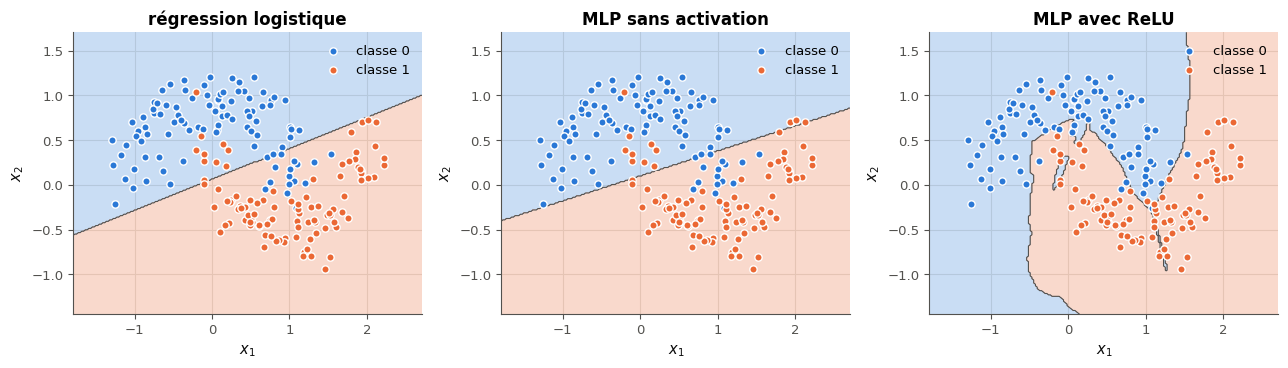

✅ Ex 17.11a : Bravo !
✅ Ex 17.11b : Exact !
✅ Ex 17.11c : Bien joué !


In [28]:
if any(answer is ... or answer is None for answer in [beats_lr_11, agree_11, relu_11]):
    print("⏳ Ex 17.11 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    logreg_11 = fit_quietly(LogisticRegression(), Xtr_11, ytr_11)
    flat_11 = fit_quietly(MLPClassifier((100, 100), activation="identity", solver="lbfgs", max_iter=3000, random_state=0),
                          Xtr_11, ytr_11)
    bent_11 = fit_quietly(MLPClassifier((100, 100), activation="relu", solver="lbfgs", max_iter=3000, random_state=0),
                          Xtr_11, ytr_11)
    n_params_11 = sum(W.size for W in flat_11.coefs_) + sum(b.size for b in flat_11.intercepts_)
    acc_11 = {name: model.score(Xte_11, yte_11) for name, model in
              [("logistic regression", logreg_11), ("MLP without activation", flat_11), ("MLP with ReLU", bent_11)]}
    for name, acc in acc_11.items():
        print(f"{name:24s} test accuracy {acc:.3f}")
    agreement_11 = float(np.mean(flat_11.predict(Xte_11) == logreg_11.predict(Xte_11)))
    print(f"MLP without activation: {n_params_11} parameters · same class as the logistic regression on {agreement_11:.1%} of the test points")
    W_eq_11 = flat_11.coefs_[0] @ flat_11.coefs_[1] @ flat_11.coefs_[2]       # the collapsed weights (2, 1)
    print("direction of the collapsed weights:", np.round(W_eq_11.ravel() / np.linalg.norm(W_eq_11), 3).tolist(),
          "· of the logistic regression:", np.round(logreg_11.coef_.ravel() / np.linalg.norm(logreg_11.coef_), 3).tolist())
    fig_11, axes_11 = plt.subplots(1, 3, figsize=(13, 3.8))
    for ax, (name, model) in zip(axes_11, [("régression logistique", logreg_11), ("MLP sans activation", flat_11),
                                           ("MLP avec ReLU", bent_11)]):
        wb.plot.plot_decision_boundary(model, Xte_11, yte_11, ax=ax, title=name)
    plt.tight_layout()
    plt.show()
    wb.check("17.11a", beats_lr_11)
    wb.check("17.11b", agree_11)
    wb.check("17.11c", relu_11)

Dans tes notes : combien de nombres suffisent à décrire la frontière du MLP sans activation, malgré ses milliers de paramètres ? Compare les deux directions de poids affichées : d'où peuvent venir les écarts entre ce MLP et la régression logistique ? Qu'est-ce que la ReLU a changé à la frontière ?

💡 Le MLP sans activation calcule une application affine de ses deux entrées, suivie de la sigmoïde de sortie : c'est une régression logistique, et sa frontière est une droite, décrite par trois nombres (deux poids et un biais), quels que soient ses 10 000 paramètres. Ici, son accuracy de test (0,860) est même un peu **inférieure** à celle de la régression logistique (0,875), et les deux modèles donnent la même classe sur 97,5 % des points de test. Les petits écarts viennent de l'entraînement, pas du modèle : la pénalité L2 de `MLPClassifier` (`alpha`) porte sur les 10 000 poids et non sur les deux poids effondrés, et `lbfgs` s'arrête quand la loss ne baisse plus. Avec ReLU, la frontière devient une ligne brisée qui suit les lunes : 0,955 d'accuracy. Sur quatre autres tirages des lunes, le MLP sans activation reste à moins de 1,5 point de la régression logistique, et le MLP ReLU au-dessus de 0,91.

### Ex 17.12 — identity, step, relu, leaky_relu et leurs dérivées 🔨 ★ ⏱️ 15 min
**Objectif :** écrire les activations linéaires par morceaux et leurs dérivées, avec la convention de PyTorch aux coudes.  
**Prérequis :** ✏️ 17.2 · fiche §17.3.1, §17.4, §17.5 (encadré sur la dérivée en un point anguleux) · **Fil rouge :** synthétique · **mylearn :** `nn/activations.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/activations.py` (créé par `python tools/start_chapter.py 17`), lis la docstring de chaque fonction, remplace les `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy et la bibliothèque standard seulement (`math.erf` pour GELU) ; SciPy et PyTorch sont les **oracles** des tests. La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à SciPy, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch17_activations.py -q` les lance tous dans un terminal (la docstring du module dit `pytest tests/ -q` : préfère cette commande du chapitre, plus courte et plus lisible). Les tests sont écrits comme te le fera faire 🛠️ 17.22 : un test paramétré par propriété, exécuté sur toute la famille (`[relu]`, `[softplus-beta2]`, `[gelu-approx_derivative]`…).

**Contrat commun** (les docstrings, plus ces précisions que vérifient les tests) : chaque fonction rend un **nouveau** tableau `float64` de la forme de `z` (un tableau de dimension 0, ou un `np.float64`, pour un nombre seul), jamais une vue de `z`, qu'elle laisse intact ; une liste d'entiers est acceptée ; aucune fonction n'émet de `RuntimeWarning` (débordement, valeur invalide, division par zéro) ni ne rend de valeur infinie pour des entrées entre $-1\,000$ et $1\,000$ ; chaque dérivée prend la **pré-activation** `z` et vaut, aux points anguleux, la valeur de PyTorch.

Écris `identity`, `step`, `relu` et `leaky_relu`, et leurs quatre dérivées `..._derivative`. **Contrat** propre à ces fonctions : `step(z, threshold, low, high)` rend `high` dès que $z \ge$ `threshold` et `low` strictement en dessous ; sa dérivée est nulle partout ; $\mathrm{ReLU}'(0) = 0$ et $\mathrm{leaky}'(0) =$ `negative_slope`, comme PyTorch ; la pente par défaut de `leaky_relu` est 0,01.

La vérification essaie les exemples de la docstring, compare `relu` et `step` à NumPy sur une grille de $-6$ à $6$, vérifie que `identity` rend une copie, puis lance les tests de l'exercice (`-k "identity or step or relu"`).

Dans tes notes : pourquoi `identity` ne peut-elle pas se contenter de `return np.asarray(z, dtype=float)` ? Quel test de la batterie le montre ?

In [29]:
if True:
    A = mylearn.nn.activations
    same("17.12", "identity([-2, 0, 2])", A.identity([-2, 0, 2]), [-2.0, 0.0, 2.0])
    same("17.12", "step([-2, 0, 2])", A.step([-2.0, 0.0, 2.0]), [0.0, 1.0, 1.0])
    same("17.12", "step([-2, 0, 2], low=-1)", A.step([-2.0, 0.0, 2.0], low=-1.0), [-1.0, 1.0, 1.0])
    same("17.12", "relu_derivative([-2, 0, 2])", A.relu_derivative([-2.0, 0.0, 2.0]), [0.0, 0.0, 1.0])
    same("17.12", "leaky_relu([-2, 0, 2], negative_slope=0.1)", A.leaky_relu([-2.0, 0.0, 2.0], negative_slope=0.1), [-0.2, 0.0, 2.0])
    same("17.12", "leaky_relu_derivative([-2, 0, 2], negative_slope=0.1)",
         A.leaky_relu_derivative([-2.0, 0.0, 2.0], negative_slope=0.1), [0.1, 0.1, 1.0])
if True:
    A = mylearn.nn.activations
    same("17.12", "relu sur z de -6 à 6, comme np.maximum", A.relu(GRID), np.maximum(GRID, 0.0))
    same("17.12", "step(z, threshold=0.5, low=-1, high=2) sur la grille", A.step(GRID, threshold=0.5, low=-1.0, high=2.0),
         -1.0 + 3.0 * np.heaviside(GRID - 0.5, 1.0))
    z_12 = np.array([1.0, 2.0, 3.0])
    out_12 = A.identity(z_12)
    verdict("17.12", isinstance(out_12, np.ndarray) and not np.shares_memory(out_12, z_12),
            "identity rend un nouveau tableau (le modifier ne touche pas z).",
            "identity(z) partage la mémoire de z : modifier le résultat modifierait z (np.asarray ne copie pas un tableau float64).")
if written(lambda: mylearn.nn.activations.relu([1.0])):
    run_mylearn_tests(impl="ref", module="activations", keyword="identity or step or relu")
else:
    print("⏳ Ex 17.12 : les tests attendent tes fonctions.")

✅ Ex 17.12 : identity([-2, 0, 2]) : [-2.0, 0.0, 2.0], comme attendu.
✅ Ex 17.12 : step([-2, 0, 2]) : [0.0, 1.0, 1.0], comme attendu.
✅ Ex 17.12 : step([-2, 0, 2], low=-1) : [-1.0, 1.0, 1.0], comme attendu.
✅ Ex 17.12 : relu_derivative([-2, 0, 2]) : [0.0, 0.0, 1.0], comme attendu.
✅ Ex 17.12 : leaky_relu([-2, 0, 2], negative_slope=0.1) : [-0.2, 0.0, 2.0], comme attendu.
✅ Ex 17.12 : leaky_relu_derivative([-2, 0, 2], negative_slope=0.1) : [0.1, 0.1, 1.0], comme attendu.
✅ Ex 17.12 : relu sur z de -6 à 6, comme np.maximum : un tableau (1201,), comme attendu.
✅ Ex 17.12 : step(z, threshold=0.5, low=-1, high=2) sur la grille : un tableau (1201,), comme attendu.
✅ Ex 17.12 : identity rend un nouveau tableau (le modifier ne touche pas z).


pytest: 75 passed, 184 deselected in 4.34s


💡 `np.asarray(z, dtype=float)` ne copie pas un tableau qui est déjà en `float64` : la fonction rendrait **le** tableau de l'appelant, et un `out[...] = ...` ultérieur modifierait ses données. Le test `test_elementwise_does_not_modify_or_share_its_input[identity]` le vérifie avec `np.shares_memory`. `np.array(z, dtype=float)` copie toujours ; pour les autres fonctions, le calcul crée déjà un nouveau tableau, mais pas pour l'identité.

### Ex 17.13 — Sigmoïde, tanh et softplus sans débordement 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire les fonctions lisses de base et leurs dérivées sans aucun débordement, même pour des entrées de ±1 000.  
**Prérequis :** Ex 17.12 · fiche §17.6, section sur le calcul sans débordement · ch. 13 (sigmoïde stable) · **Fil rouge :** synthétique · **mylearn :** `nn/activations.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/activations.py` (créé par `python tools/start_chapter.py 17`), lis la docstring de chaque fonction, remplace les `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy et la bibliothèque standard seulement (`math.erf` pour GELU) ; SciPy et PyTorch sont les **oracles** des tests. La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à SciPy, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch17_activations.py -q` les lance tous dans un terminal (la docstring du module dit `pytest tests/ -q` : préfère cette commande du chapitre, plus courte et plus lisible). Les tests sont écrits comme te le fera faire 🛠️ 17.22 : un test paramétré par propriété, exécuté sur toute la famille (`[relu]`, `[softplus-beta2]`, `[gelu-approx_derivative]`…).

**Contrat commun** (les docstrings, plus ces précisions que vérifient les tests) : chaque fonction rend un **nouveau** tableau `float64` de la forme de `z` (un tableau de dimension 0, ou un `np.float64`, pour un nombre seul), jamais une vue de `z`, qu'elle laisse intact ; une liste d'entiers est acceptée ; aucune fonction n'émet de `RuntimeWarning` (débordement, valeur invalide, division par zéro) ni ne rend de valeur infinie pour des entrées entre $-1\,000$ et $1\,000$ ; chaque dérivée prend la **pré-activation** `z` et vaut, aux points anguleux, la valeur de PyTorch.

Écris `sigmoid`, `tanh` et `softplus`, et leurs trois dérivées. **Contrat** propre à ces fonctions : `sigmoid(-1000)` vaut 0 et `sigmoid(1000)` vaut 1, sans avertissement, et les petites probabilités sont gardées (`sigmoid(-700)` est comparé à SciPy avec une tolérance **relative**) ; `softplus(z, beta, threshold)` rend `z` lui-même seulement quand `beta * z` est **strictement** supérieur à `threshold` (convention de PyTorch), et $\log(1 + e^{\beta z})/\beta$ sinon, seuil compris ; sa dérivée vaut exactement 1 au-dessus du seuil.

La vérification essaie les exemples de la docstring, appelle chaque fonction sur des valeurs extrêmes en guettant les avertissements, compare `sigmoid(-700)` et `softplus` à SciPy et NumPy, puis lance les tests (`-k "sigmoid or tanh or softplus"`).

Dans tes notes : quelle est la plus petite valeur strictement positive que rend ta sigmoïde, et pour quel $z$ environ ? Pourquoi la forme $1 - 1/(1 + e^{z})$, mathématiquement égale à $\sigma(z)$, ne la garderait-elle pas ?

In [30]:
if True:
    A = mylearn.nn.activations
    same("17.13", "sigmoid([-2, 0, 2])", A.sigmoid([-2.0, 0.0, 2.0]), special.expit([-2.0, 0.0, 2.0]))
    same("17.13", "sigmoid_derivative([-2, 0, 2])", A.sigmoid_derivative([-2.0, 0.0, 2.0]), [0.10499358540350652, 0.25, 0.10499358540350652])
    same("17.13", "tanh_derivative([-2, 0, 2])", A.tanh_derivative([-2.0, 0.0, 2.0]), 1 - np.tanh([-2.0, 0.0, 2.0]) ** 2)
    same("17.13", "softplus([-2, 0, 2])", A.softplus([-2.0, 0.0, 2.0]), np.logaddexp(0.0, [-2.0, 0.0, 2.0]))
    same("17.13", "softplus_derivative([-2, 0, 2])", A.softplus_derivative([-2.0, 0.0, 2.0]), special.expit([-2.0, 0.0, 2.0]))
if True:
    A = mylearn.nn.activations
    for name_13 in ["sigmoid", "sigmoid_derivative", "tanh", "tanh_derivative", "softplus", "softplus_derivative"]:
        values_13, alarms_13 = quiet(getattr(A, name_13), EXTREME.copy())
        finite_13 = bool(np.all(np.isfinite(np.asarray(values_13, dtype=float))))
        verdict("17.13", finite_13 and not alarms_13, f"{name_13} sur z = ±1000, ±700, ±40, 0 : fini et sans avertissement.",
                f"{name_13} sur z = ±1000, ±700, ±40, 0 : " + (f"avertissement « {alarms_13[0]} »" if alarms_13 else "une valeur infinie ou nan")
                + " (relis le premier principe de la section sur le calcul sans débordement).")
    same("17.13", "sigmoid(-700) (tolérance relative)", A.sigmoid([-700.0]), special.expit([-700.0]), rtol=1e-6, atol=0.0)
    same("17.13", "softplus(z, beta=2, threshold=10) sur la grille (seuil compris, en z = 5)", A.softplus(GRID, beta=2.0, threshold=10.0),
         np.where(2 * GRID > 10, GRID, np.logaddexp(0.0, 2 * GRID) / 2), rtol=1e-9, atol=0.0)
if written(lambda: mylearn.nn.activations.sigmoid([1.0])):
    run_mylearn_tests(impl="ref", module="activations", keyword="sigmoid or tanh or softplus")
else:
    print("⏳ Ex 17.13 : les tests attendent tes fonctions.")

✅ Ex 17.13 : sigmoid([-2, 0, 2]) : [0.11920292, 0.5, 0.88079708], comme attendu.
✅ Ex 17.13 : sigmoid_derivative([-2, 0, 2]) : [0.10499359, 0.25, 0.10499359], comme attendu.
✅ Ex 17.13 : tanh_derivative([-2, 0, 2]) : [0.07065082, 1.0, 0.07065082], comme attendu.
✅ Ex 17.13 : softplus([-2, 0, 2]) : [0.12692801, 0.69314718, 2.12692801], comme attendu.
✅ Ex 17.13 : softplus_derivative([-2, 0, 2]) : [0.11920292, 0.5, 0.88079708], comme attendu.
✅ Ex 17.13 : sigmoid sur z = ±1000, ±700, ±40, 0 : fini et sans avertissement.
✅ Ex 17.13 : sigmoid_derivative sur z = ±1000, ±700, ±40, 0 : fini et sans avertissement.
✅ Ex 17.13 : tanh sur z = ±1000, ±700, ±40, 0 : fini et sans avertissement.
✅ Ex 17.13 : tanh_derivative sur z = ±1000, ±700, ±40, 0 : fini et sans avertissement.
✅ Ex 17.13 : softplus sur z = ±1000, ±700, ±40, 0 : fini et sans avertissement.
✅ Ex 17.13 : softplus_derivative sur z = ±1000, ±700, ±40, 0 : fini et sans avertissement.
✅ Ex 17.13 : sigmoid(-700) (tolérance relative) : [0

pytest: 66 passed, 193 deselected in 4.26s


💡 Avec la forme $e^{z}/(1 + e^{z})$ pour $z < 0$, la sigmoïde suit $e^{z}$ jusqu'au plus petit nombre représentable : environ $5 \times 10^{-324}$ (un nombre « sous-normal ») en $z = -745$, puis 0 dès $z = -746$. La forme $1 - 1/(1 + e^{z})$ soustrait deux nombres presque égaux à 1 : dès que $e^{z}$ passe sous $10^{-16}$ environ (vers $z = -37$), $1/(1 + e^{z})$ s'arrondit à 1 et la différence vaut exactement 0. On perd alors toutes les petites probabilités, et un `log` de la sortie vaut `-inf`.

### Ex 17.14 — ELU, SiLU, GELU et le registre get_activation 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire les ReLU lissées, GELU exacte et approchée, et le registre qui associe un nom à un couple (f, f′).  
**Prérequis :** Ex 17.13 · fiche §17.6 (encadré sur Φ et erf), §17.7 · **Fil rouge :** synthétique · **mylearn :** `nn/activations.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/activations.py` (créé par `python tools/start_chapter.py 17`), lis la docstring de chaque fonction, remplace les `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy et la bibliothèque standard seulement (`math.erf` pour GELU) ; SciPy et PyTorch sont les **oracles** des tests. La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à SciPy, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch17_activations.py -q` les lance tous dans un terminal (la docstring du module dit `pytest tests/ -q` : préfère cette commande du chapitre, plus courte et plus lisible). Les tests sont écrits comme te le fera faire 🛠️ 17.22 : un test paramétré par propriété, exécuté sur toute la famille (`[relu]`, `[softplus-beta2]`, `[gelu-approx_derivative]`…).

**Contrat commun** (les docstrings, plus ces précisions que vérifient les tests) : chaque fonction rend un **nouveau** tableau `float64` de la forme de `z` (un tableau de dimension 0, ou un `np.float64`, pour un nombre seul), jamais une vue de `z`, qu'elle laisse intact ; une liste d'entiers est acceptée ; aucune fonction n'émet de `RuntimeWarning` (débordement, valeur invalide, division par zéro) ni ne rend de valeur infinie pour des entrées entre $-1\,000$ et $1\,000$ ; chaque dérivée prend la **pré-activation** `z` et vaut, aux points anguleux, la valeur de PyTorch.

Écris `elu`, `silu` et `gelu`, leurs dérivées, et `get_activation`. **Contrat** propre à ces fonctions : $\mathrm{ELU}'(0) = \alpha$ (PyTorch) ; `gelu` et `gelu_derivative` acceptent `approximate="none"` (la formule exacte, avec `math.erf` vectorisé) ou `approximate="tanh"` (l'approximation de la fiche), et lèvent `ValueError` pour toute autre valeur, `None` compris ; `get_activation(name)` ignore la casse, connaît l'alias `"swish"` de `"silu"`, rend un couple fait des fonctions **du module elles-mêmes** (`get_activation("relu")` est `(relu, relu_derivative)`), et lève `ValueError` pour un nom inconnu, avec un message qui donne les dix noms valides.

La vérification essaie les exemples de la docstring, compare `gelu` à $z\,\Phi(z)$ calculé avec `scipy.special.erf`, essaie des noms et une approximation inconnus, puis lance les tests (`-k "(elu or silu or gelu or get_activation) and not relu"`).

Dans tes notes : pourquoi `get_activation("softmax")` doit-il lever une erreur, alors que ta librairie a une fonction `softmax` ?

In [31]:
if True:
    A = mylearn.nn.activations
    same("17.14", "elu([-2, 0, 2])", A.elu([-2.0, 0.0, 2.0]), [-0.8646647167633873, 0.0, 2.0])
    same("17.14", "elu_derivative([0], alpha=1.5)", A.elu_derivative([0.0], alpha=1.5), [1.5])
    same("17.14", "silu_derivative([-2, 0, 2])", A.silu_derivative([-2.0, 0.0, 2.0]), [-0.09078424878489121, 0.5, 1.0907842487848914])
    exact_14 = GRID * 0.5 * (1 + special.erf(GRID / np.sqrt(2)))
    same("17.14", "gelu sur la grille, comme z Φ(z) avec scipy.special.erf", A.gelu(GRID), exact_14)
    same("17.14", 'gelu([-2, 0, 2], approximate="tanh")', A.gelu([-2.0, 0.0, 2.0], approximate="tanh"),
         [-0.04540230591222698, 0.0, 1.954597694087773])
    same("17.14", 'gelu_derivative([-2, 0, 2], approximate="tanh")', A.gelu_derivative([-2.0, 0.0, 2.0], approximate="tanh"),
         [-0.08609925660415786, 0.5, 1.0860992566041579])
if True:
    A = mylearn.nn.activations
    try:
        A.gelu([1.0], approximate="exact")
        print('❌ Ex 17.14 : gelu(z, approximate="exact") devrait lever ValueError (les deux noms valides sont "none" et "tanh").')
    except ValueError as exc_14:
        print(f'✅ Ex 17.14 : gelu(z, approximate="exact") lève ValueError : {exc_14}')
    pair_14 = A.get_activation("ReLU")
    verdict("17.14", tuple(pair_14) == (A.relu, A.relu_derivative), 'get_activation("ReLU") rend (relu, relu_derivative), les fonctions du module.',
            f'get_activation("ReLU") rend {pair_14!r} : attendu (relu, relu_derivative), les fonctions du module elles-mêmes.')
    verdict("17.14", A.get_activation("swish")[0] is A.silu, '"swish" est un alias de silu.', 'get_activation("swish") doit rendre silu.')
    try:
        A.get_activation("sigmoïde")
        print('❌ Ex 17.14 : get_activation("sigmoïde") devrait lever ValueError.')
    except ValueError as exc_14:
        print(f"✅ Ex 17.14 : un nom inconnu lève ValueError : {exc_14}")
if written(lambda: mylearn.nn.activations.gelu([1.0])):
    run_mylearn_tests(impl="ref", module="activations", keyword="(elu or silu or gelu or get_activation) and not relu")
else:
    print("⏳ Ex 17.14 : les tests attendent tes fonctions.")

✅ Ex 17.14 : elu([-2, 0, 2]) : [-0.86466472, 0.0, 2.0], comme attendu.
✅ Ex 17.14 : elu_derivative([0], alpha=1.5) : [1.5], comme attendu.
✅ Ex 17.14 : silu_derivative([-2, 0, 2]) : [-0.09078425, 0.5, 1.09078425], comme attendu.
✅ Ex 17.14 : gelu sur la grille, comme z Φ(z) avec scipy.special.erf : un tableau (1201,), comme attendu.
✅ Ex 17.14 : gelu([-2, 0, 2], approximate="tanh") : [-0.04540231, 0.0, 1.95459769], comme attendu.
✅ Ex 17.14 : gelu_derivative([-2, 0, 2], approximate="tanh") : [-0.08609926, 0.5, 1.08609926], comme attendu.
✅ Ex 17.14 : gelu(z, approximate="exact") lève ValueError : approximate must be "none" or "tanh", got 'exact'
✅ Ex 17.14 : get_activation("ReLU") rend (relu, relu_derivative), les fonctions du module.
✅ Ex 17.14 : "swish" est un alias de silu.
✅ Ex 17.14 : un nom inconnu lève ValueError : unknown activation 'sigmoïde'; valid names: identity, step, relu, leaky_relu, elu, softplus, sigmoid, tanh, silu, gelu (alias: swish for silu)


pytest: 78 passed, 181 deselected in 3.73s


💡 Le registre rend des couples `(f, f′)` de fonctions **élément par élément**, que `mlp_forward` applique à chaque case et que `mlp_backward` multipliera case par case (ch. 18). La softmax n'en est pas une : chaque sortie dépend de toute la ligne, et sa « dérivée » est une Jacobienne $(K, K)$ par exemple, pas un tableau de la forme de `z`. La mettre dans le registre ferait croire qu'on peut l'utiliser comme une activation cachée ; en sortie, elle se traite à part, avec la loss (ch. 18).

## Partie B · La softmax

La softmax stable et son logarithme (17.15), sa Jacobienne pour un batch (17.16), puis une chasse aux `nan` dans la sortie d'un petit réseau (17.17).

### Ex 17.15 — Softmax et log_softmax stables (astuce log-sum-exp) 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire une softmax et une log-softmax qui ne débordent jamais, le long de n'importe quel axe.  
**Prérequis :** Ex 17.13 · fiche §17.8, section sur le calcul sans débordement · ch. 13 (`logsumexp`) · **Fil rouge :** synthétique · **mylearn :** `nn/activations.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/activations.py` (créé par `python tools/start_chapter.py 17`), lis la docstring de chaque fonction, remplace les `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy et la bibliothèque standard seulement (`math.erf` pour GELU) ; SciPy et PyTorch sont les **oracles** des tests. La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à SciPy, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch17_activations.py -q` les lance tous dans un terminal (la docstring du module dit `pytest tests/ -q` : préfère cette commande du chapitre, plus courte et plus lisible). Les tests sont écrits comme te le fera faire 🛠️ 17.22 : un test paramétré par propriété, exécuté sur toute la famille (`[relu]`, `[softplus-beta2]`, `[gelu-approx_derivative]`…).

Écris `softmax` et `log_softmax`. **Contrat** (les docstrings, plus ces précisions que vérifient les tests) : les deux fonctions rendent un nouveau tableau `float64` de la forme de `z`, laissent `z` intact, et lèvent `ValueError` pour un nombre seul (0 dimension) ; `axis` désigne l'axe des classes (par défaut le dernier), et n'importe quel axe d'un tableau 1-D, 2-D ou 3-D doit marcher ; les probabilités sont positives et somment à 1 le long de `axis` ; aucun avertissement ni `nan` pour des logits de l'ordre de $\pm 1\,000$ (`softmax`) ou de $10^4$ (`log_softmax`, qui ne calcule jamais `log(0)`).

La vérification essaie les exemples de la docstring et des logits énormes, compare tes fonctions à `scipy.special.softmax` et `log_softmax` sur un batch le long des deux axes, essaie un nombre seul, puis lance les tests (`-k "softmax and not derivative"`).

Dans tes notes : la softmax de `[-1000, -1001, -1003]` sans soustraction du maximum, que donne-t-elle, et pourquoi ? Le soustraire change-t-il le résultat mathématique ?

In [32]:
if True:
    A = mylearn.nn.activations
    same("17.15", "softmax([1, 2, 3])", A.softmax([1.0, 2.0, 3.0]), special.softmax([1.0, 2.0, 3.0]))
    big_15, alarms_15 = quiet(A.softmax, [1001.0, 1002.0, 1003.0])
    same("17.15", "softmax([1001, 1002, 1003])", big_15, special.softmax([1.0, 2.0, 3.0]))
    verdict("17.15", not alarms_15, "softmax de logits de l'ordre de 1 000 : aucun avertissement.",
            f"softmax([1001, 1002, 1003]) émet « {alarms_15[0] if alarms_15 else ''} » : soustrais d'abord le maximum.")
    logp_15, alarms_15 = quiet(A.log_softmax, [0.0, 10000.0])
    same("17.15", "log_softmax([0, 10000])", logp_15, [-10000.0, 0.0])
    verdict("17.15", not alarms_15, "log_softmax([0, 10000]) : aucun avertissement.",
            f"log_softmax([0, 10000]) émet « {alarms_15[0] if alarms_15 else ''} » : z − logsumexp(z), jamais log(softmax(z)).")
if True:
    A = mylearn.nn.activations
    batch_15 = np.random.default_rng(1715).normal(scale=3.0, size=(4, 6))
    same("17.15", "softmax d'un batch (4, 6), axe des classes -1", A.softmax(batch_15), special.softmax(batch_15, axis=-1))
    same("17.15", "softmax du même batch avec axis=0", A.softmax(batch_15, axis=0), special.softmax(batch_15, axis=0))
    same("17.15", "log_softmax du batch", A.log_softmax(batch_15), special.log_softmax(batch_15, axis=-1))
    try:
        A.softmax(3.0)
        print("❌ Ex 17.15 : softmax(3.0) devrait lever ValueError (un nombre seul n'a pas d'axe de classes).")
    except ValueError as exc_15:
        print(f"✅ Ex 17.15 : softmax d'un nombre seul lève ValueError : {exc_15}")
if written(lambda: mylearn.nn.activations.softmax([1.0, 2.0])):
    run_mylearn_tests(impl="ref", module="activations", keyword="softmax and not derivative")
else:
    print("⏳ Ex 17.15 : les tests attendent tes fonctions.")

✅ Ex 17.15 : softmax([1, 2, 3]) : [0.09003057, 0.24472847, 0.66524096], comme attendu.
✅ Ex 17.15 : softmax([1001, 1002, 1003]) : [0.09003057, 0.24472847, 0.66524096], comme attendu.
✅ Ex 17.15 : softmax de logits de l'ordre de 1 000 : aucun avertissement.
✅ Ex 17.15 : log_softmax([0, 10000]) : [-10000.0, 0.0], comme attendu.
✅ Ex 17.15 : log_softmax([0, 10000]) : aucun avertissement.
✅ Ex 17.15 : softmax d'un batch (4, 6), axe des classes -1 : un tableau (4, 6), comme attendu.
✅ Ex 17.15 : softmax du même batch avec axis=0 : un tableau (4, 6), comme attendu.
✅ Ex 17.15 : log_softmax du batch : un tableau (4, 6), comme attendu.
✅ Ex 17.15 : softmax d'un nombre seul lève ValueError : softmax needs an array of at least one dimension (the classes), got a single number


pytest: 29 passed, 230 deselected in 3.70s


💡 Sans soustraction, les trois exponentielles s'arrondissent à 0 (elles sont sous $e^{-745}$), et le quotient $0/0$ vaut `nan`, avec un avertissement « invalid value ». Soustraire le maximum ne change rien mathématiquement ($\mathrm{softmax}(\mathbf{z} - m) = \mathrm{softmax}(\mathbf{z})$) : le plus grand terme devient $e^0 = 1$, la somme vaut au moins 1, et le résultat est $(0{,}7054 ;\ 0{,}2595 ;\ 0{,}0351)$, comme pour les logits $0, -1, -3$.

### Ex 17.16 — La Jacobienne de la softmax en NumPy 🔨 ★★★ ⏱️ 30 min
**Objectif :** écrire la Jacobienne de la softmax pour un exemple et pour un batch, sans boucle sur les exemples.  
**Prérequis :** Ex 17.15 · ∂ 17.7 · fiche §17.8 (encadré sur la Jacobienne) · **Fil rouge :** synthétique · **mylearn :** `nn/activations.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/activations.py` (créé par `python tools/start_chapter.py 17`), lis la docstring de chaque fonction, remplace les `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy et la bibliothèque standard seulement (`math.erf` pour GELU) ; SciPy et PyTorch sont les **oracles** des tests. La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à SciPy, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch17_activations.py -q` les lance tous dans un terminal (la docstring du module dit `pytest tests/ -q` : préfère cette commande du chapitre, plus courte et plus lisible). Les tests sont écrits comme te le fera faire 🛠️ 17.22 : un test paramétré par propriété, exécuté sur toute la famille (`[relu]`, `[softplus-beta2]`, `[gelu-approx_derivative]`…).

Écris `softmax_derivative`. **Contrat** : pour des logits de forme `(K,)`, la fonction rend la matrice `(K, K)` de case `[i, j]` $= \partial p_i / \partial z_j = p_i(\delta_{ij} - p_j)$ ; pour un batch `(n, K)`, un tableau `(n, K, K)`, une matrice par exemple ; `ValueError` pour toute autre dimension ; aucun avertissement pour des logits de l'ordre de $\pm 1\,000$ ; `z` reste intact.

La vérification essaie les exemples de la docstring, compare ta Jacobienne à des différences centrées de `scipy.special.softmax` sur un batch de 5 exemples, vérifie la symétrie et les lignes de somme nulle, puis lance les tests (`-k softmax_derivative`).

Dans tes notes : combien de nombres contient le résultat pour un batch de 64 exemples et un vocabulaire de 50 000 tokens ? Pourquoi aucune bibliothèque ne forme ce tableau pendant l'entraînement ?

In [33]:
def numeric_jacobian_16(z, h=1e-6):
    """Central differences of scipy.special.softmax along the last axis: entry [..., i, j] = dp_i / dz_j."""
    K = z.shape[-1]
    J = np.empty(z.shape[:-1] + (K, K))
    for j in range(K):
        step = np.zeros(K)
        step[j] = h
        J[..., :, j] = (special.softmax(z + step, axis=-1) - special.softmax(z - step, axis=-1)) / (2 * h)
    return J


if True:
    A = mylearn.nn.activations
    same("17.16", "softmax_derivative([0, 0])", A.softmax_derivative([0.0, 0.0]), [[0.25, -0.25], [-0.25, 0.25]])
    z_16 = np.random.default_rng(1716).normal(scale=2.0, size=(5, 4))
    J_16 = np.asarray(A.softmax_derivative(z_16), dtype=float)
    verdict("17.16", J_16.shape == (5, 4, 4), "5 exemples de 4 logits : un tableau (5, 4, 4), une Jacobienne par exemple.",
            f"attendu la forme (5, 4, 4), reçu {J_16.shape}.")
    if J_16.shape == (5, 4, 4):
        same("17.16", "Jacobiennes du batch, comme les différences centrées de scipy.special.softmax", J_16,
             numeric_jacobian_16(z_16), rtol=1e-6, atol=1e-8)
        verdict("17.16", np.allclose(J_16, np.swapaxes(J_16, 1, 2)) and np.allclose(J_16.sum(axis=2), 0.0, atol=1e-12),
                "chaque Jacobienne est symétrique, et ses lignes somment à 0.",
                "une Jacobienne de la softmax est symétrique, et ses lignes somment à 0 : vérifie les axes de ton produit.")
if written(lambda: mylearn.nn.activations.softmax_derivative([0.0, 1.0])):
    run_mylearn_tests(impl="ref", module="activations", keyword="softmax_derivative")
else:
    print("⏳ Ex 17.16 : les tests attendent ta fonction.")

✅ Ex 17.16 : softmax_derivative([0, 0]) : [[0.25, -0.25], [-0.25, 0.25]], comme attendu.
✅ Ex 17.16 : 5 exemples de 4 logits : un tableau (5, 4, 4), une Jacobienne par exemple.
✅ Ex 17.16 : Jacobiennes du batch, comme les différences centrées de scipy.special.softmax : un tableau (5, 4, 4), comme attendu.
✅ Ex 17.16 : chaque Jacobienne est symétrique, et ses lignes somment à 0.


pytest: 11 passed, 248 deselected in 5.64s


💡 $64 \times 50\,000^2 = 1{,}6 \times 10^{11}$ nombres, soit 640 Go en `float32` : impossible. La rétropropagation n'a besoin que du produit d'un vecteur par la Jacobienne, $\mathbf{g}\mathbf{J} = \mathbf{p} \odot (\mathbf{g} - (\mathbf{g}\cdot\mathbf{p}))$, en $O(K)$ opérations par exemple (∂ 17.7) ; avec la cross-entropy, il se simplifie même en $\mathbf{p} - \mathbf{y}$.

### Ex 17.17 — Chasse au bug : nan, inf et mauvais axe 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver quatre erreurs dans la sortie d'un petit réseau, dont trois qui ne se voient que sur des valeurs extrêmes.  
**Prérequis :** Ex 17.13 · Ex 17.15 · fiche §17.6 (encadré sur les dérivées), section sur le calcul sans débordement · **Parcours :** C

Un collègue a écrit `forward_17`, la passe avant d'un petit réseau tanh à une couche cachée : elle rend les probabilités des classes, la cross-entropy moyenne du batch, et la pente $\tanh'(z_1)$ de chaque neurone caché, que la rétropropagation du ch. 18 utilisera. Sur ses données de test, tout semble marcher. Il y a pourtant **quatre** erreurs : trouve-les et corrige-les dans la cellule ci-dessous, sans changer la signature ni ce que rend la fonction. Tu peux utiliser les fonctions de ta librairie (`mylearn.nn.activations`).

La vérification contrôle quatre propriétés, dans l'ordre où les erreurs se masquent (un point ne se teste que si les précédents passent) : 1) aucun débordement de l'exponentielle pour des logits de l'ordre de 1 000 ; 2) chaque ligne de probabilités somme à 1 et vaut la softmax de SciPy ; 3) une loss finie et juste quand la bonne classe d'un exemple a une probabilité qui s'arrondit à 0 ; 4) la pente vaut $\tanh'(z_1)$. Cet exercice se corrige avec `05_solutions.md`.

Dans tes notes : pour chaque erreur, quel symptôme aurait-elle eu pendant un vrai entraînement ? Lesquelles un test sur des données « normales » ne voit-il pas ?

In [34]:
rng_17 = np.random.default_rng(1717)
X_17 = rng_17.normal(size=(8, 3))
PARAMS_17 = [(rng_17.normal(size=(3, 4)), rng_17.normal(size=4)), (rng_17.normal(size=(4, 3)), rng_17.normal(size=3))]
BIG_17 = [PARAMS_17[0], (400.0 * PARAMS_17[1][0], 400.0 * PARAMS_17[1][1])]      # logits of order 1000
Y_17 = np.array([0, 1, 2, 0, 1, 2, 0, 1])


def reference_17(X, y, params):
    """What forward_17 must return, computed with SciPy (the oracle of the diagnostics)."""
    (W1, b1), (W2, b2) = params
    z1 = X @ W1 + b1
    logits = np.tanh(z1) @ W2 + b2
    return special.softmax(logits, axis=1), float(-np.mean(special.log_softmax(logits, axis=1)[np.arange(len(y)), y])), 1 - np.tanh(z1) ** 2

In [35]:
def forward_17(X, y, params):
    """Probabilities, mean cross-entropy and local slopes of a 2-layer tanh network (one row per sample)."""
    (W1, b1), (W2, b2) = params
    z1 = X @ W1 + b1
    h = np.tanh(z1)
    slope = 1.0 - np.tanh(z1) ** 2                    # fix 4: the derivative is taken at the pre-activation z1
    logits = h @ W2 + b2
    shifted = logits - logits.max(axis=1, keepdims=True)   # fix 1: no overflow
    log_proba = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))   # fix 2 (axis=1) and fix 3 (log-sum-exp)
    proba = np.exp(log_proba)
    loss = -np.mean(log_proba[np.arange(len(y)), y])
    return proba, float(loss), slope

def diagnose_17(forward):
    """The four points of 17.17, in the order in which the bugs hide each other; returns the first failing point (or 0)."""
    points = [
        (1, "aucun débordement (« overflow ») de l'exponentielle pour des logits de l'ordre de 1 000"),
        (2, "chaque LIGNE de probabilités somme à 1 et vaut la softmax de SciPy"),
        (3, "une loss finie, égale à la cross-entropy de SciPy, quand la bonne classe a une probabilité qui s'arrondit à 0"),
        (4, "slope vaut tanh'(z1), la dérivée prise en la pré-activation"),
    ]
    for k, what in points:
        try:
            if k == 1:
                (proba, _, _), alarms = quiet(forward, X_17, Y_17, BIG_17)
                ok = not [a for a in alarms if "overflow" in a]      # nan from the axis is point 2, inf from the log point 3
            elif k == 2:
                (proba, _, _), _ = quiet(forward, X_17, Y_17, BIG_17)      # its warnings belong to the other points
                want, _, _ = reference_17(X_17, Y_17, BIG_17)
                ok = np.shape(proba) == want.shape and bool(np.allclose(proba, want, atol=1e-12))
            elif k == 3:
                logits = np.tanh(X_17 @ BIG_17[0][0] + BIG_17[0][1]) @ BIG_17[1][0] + BIG_17[1][1]
                y_worst = np.argmin(logits, axis=1)               # the least likely class of each row
                (_, loss, _), alarms = quiet(forward, X_17, y_worst, BIG_17)
                _, want, _ = reference_17(X_17, y_worst, BIG_17)
                ok = not alarms and np.isfinite(float(loss)) and bool(np.isclose(float(loss), want, rtol=1e-9))
            else:
                (_, _, slope), _ = quiet(forward, X_17, Y_17, PARAMS_17)
                _, _, want = reference_17(X_17, Y_17, PARAMS_17)
                ok = np.shape(slope) == want.shape and bool(np.allclose(slope, want, atol=1e-12))
        except (NotImplementedError, MylearnMissingError):
            raise
        except Exception as exc:                                # a crash counts as a failed point
            ok, what = False, f"{what} (ton code lève {type(exc).__name__} : {str(exc)[:120]})"
        verdict("17.17", ok, f"point {k} : {what}.", f"point {k} : attendu : {what}.")
        if not ok:
            return k
    return 0


if True:
    first_17 = diagnose_17(forward_17)
    if first_17:
        print(f"⏳ Ex 17.17 : corrige d'abord le point {first_17} ; les points suivants seront vérifiés ensuite.")
    else:
        print("✅ Ex 17.17 : les quatre points sont corrigés.")

✅ Ex 17.17 : point 1 : aucun débordement (« overflow ») de l'exponentielle pour des logits de l'ordre de 1 000.
✅ Ex 17.17 : point 2 : chaque LIGNE de probabilités somme à 1 et vaut la softmax de SciPy.
✅ Ex 17.17 : point 3 : une loss finie, égale à la cross-entropy de SciPy, quand la bonne classe a une probabilité qui s'arrondit à 0.
✅ Ex 17.17 : point 4 : slope vaut tanh'(z1), la dérivée prise en la pré-activation.
✅ Ex 17.17 : les quatre points sont corrigés.


💡 Les quatre erreurs : `np.exp(logits)` déborde pour des logits de l'ordre de 1 000 (`inf / inf = nan`) : soustraire le maximum de chaque ligne ; `sum(axis=0)` normalise les **colonnes** (les classes sur tout le batch) au lieu des lignes : `axis=1` ; `np.log(proba)` vaut `-inf` quand la probabilité de la bonne classe s'arrondit à 0, et la loss devient infinie : calculer `log_softmax` par log-sum-exp ; `1 - np.tanh(h) ** 2` prend la dérivée en la **sortie** $h = \tanh(z_1)$ au lieu de la pré-activation : `1 - np.tanh(z1) ** 2` (ou `1 - h ** 2`). Sur des données ordinaires, seule l'erreur d'axe change les probabilités ; les erreurs 1 et 3 n'apparaissent qu'avec des logits extrêmes, et la 4 donne des pentes plausibles (toutes entre 0 et 1), donc des gradients faux sans aucun message.

## Partie C · Comparer les activations

Refaire la galerie avec ton code et y mesurer quatre valeurs (17.18), prédire l'effet d'une température (17.19), comparer les quatre activations de scikit-learn sur deux problèmes (17.20), puis lire des histogrammes de pré-activations (17.21).

### Ex 17.18 — Reproduire la galerie de la figure 17.22, dérivées comprises 🎨 ★★ ⏱️ 25 min
**Objectif :** tracer les dix activations de ta librairie avec leurs dérivées, et lire sur des grilles fines quatre points remarquables.  
**Prérequis :** Ex 17.14 · fiche §17.7 · **Parcours :** C

Refais la galerie de la fiche (§17.7) avec **ta** librairie : une grille de 2 × 5 graphiques, un par nom de `NAMES_18`, avec `f` en trait plein et `f′` en tirets (obtenus par `get_activation`), pour $z$ de $-4$ à $4$ et une ordonnée de $-1{,}5$ à $2{,}5$. Puis, avec tes fonctions, calcule sur des grilles **fines** (un pas de $10^{-4}$ ou moins) :
a) `zmin_silu_18` : la valeur de $z$ où SiLU est la plus petite ;
b) `min_gelu_18` : la plus petite valeur de GELU ;
c) `max_dgelu_18` : la plus grande valeur de la dérivée de GELU ;
d) `zmax_dsilu_18` : la valeur de $z > 0$ où la dérivée de SiLU est la plus grande.

Garde les valeurs telles quelles : la vérification arrondit elle-même (2 décimales pour a) et d), 3 pour b) et c)).

Dans tes notes : quelles fonctions de la galerie ont une dérivée qui dépasse 1 ? Qu'est-ce que cela change pour le produit des dérivées de la rétropropagation, par rapport à la sigmoïde ?

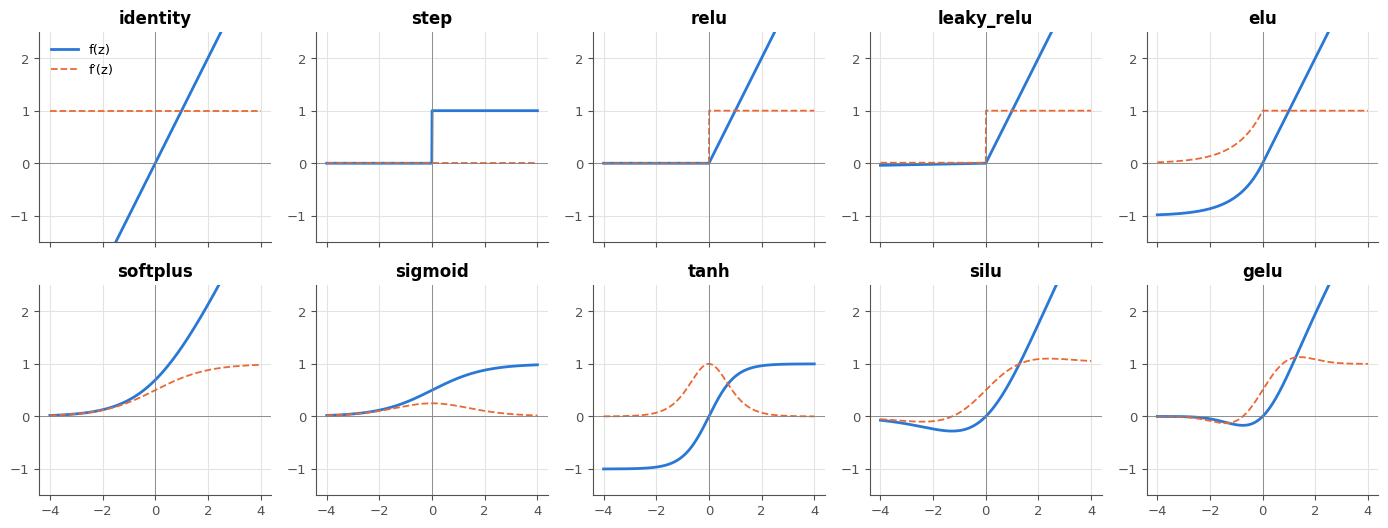

-1.27846 -0.16997120747940211 1.1289041451825208 2.3993600000000006


In [36]:
A = mylearn.nn.activations
NAMES_18 = ["identity", "step", "relu", "leaky_relu", "elu", "softplus", "sigmoid", "tanh", "silu", "gelu"]
z_18 = np.linspace(-4, 4, 801)
fig_18, axes_18 = plt.subplots(2, 5, figsize=(14, 5.4), sharex=True)
for ax, name in zip(axes_18.ravel(), NAMES_18):
    f, df = A.get_activation(name)
    ax.plot(z_18, f(z_18), lw=2, label="f(z)")
    ax.plot(z_18, df(z_18), "--", lw=1.3, label="f′(z)")
    ax.axhline(0, color="grey", lw=0.6)
    ax.axvline(0, color="grey", lw=0.6)
    ax.set_title(name)
    ax.set_ylim(-1.5, 2.5)
axes_18[0, 0].legend()
plt.tight_layout()
plt.show()

fine_18 = np.linspace(-4, 4, 800_001)                 # a step of 1e-5
zmin_silu_18 = float(fine_18[np.argmin(A.silu(fine_18))])
min_gelu_18 = float(np.min(A.gelu(fine_18)))
max_dgelu_18 = float(np.max(A.gelu_derivative(fine_18)))
positive_18 = fine_18[fine_18 > 0]
zmax_dsilu_18 = float(positive_18[np.argmax(A.silu_derivative(positive_18))])
print(zmin_silu_18, min_gelu_18, max_dgelu_18, zmax_dsilu_18)

In [37]:
wb.record("17.18a", zmin_silu_18, decimals=2, mistakes={"c'est la valeur minimale de SiLU ; on demande OÙ elle est atteinte": -0.28,
                                                            "c'est l'abscisse du minimum de GELU": -0.75})
wb.record("17.18b", min_gelu_18, decimals=3, mistakes={"c'est le minimum de SiLU ; on demande celui de GELU": -0.278,
                                                       "c'est l'abscisse du minimum ; on demande la valeur": -0.752})
wb.record("17.18c", max_dgelu_18, decimals=3, mistakes={"c'est le maximum de la dérivée de SiLU ; on demande celui de GELU": 1.100,
                                                        "c'est l'abscisse du maximum ; on demande la valeur": 1.414})
wb.record("17.18d", zmax_dsilu_18, decimals=2, mistakes={"c'est la valeur maximale de la dérivée ; on demande OÙ elle est atteinte": 1.10,
                                                         "c'est l'abscisse du maximum de la dérivée de GELU": 1.41})

WB_ANSWER {"decimals": 2, "hash": "3c67eb2e605284a7bd25c9da0a72060cbff42bb98a8f5c80629929ff3c27cac8", "hash_coarse": "9a84859af8eb542f639ee180b6eaab81982b57f28c851e3fe0cb926858036ca9", "id": "17.18a", "kind": "float", "magnitude": 0, "mistakes": {"777037207e170285a8dbcf431bfa0fd8243265010e2e3546899bed04db32377b": "c'est la valeur minimale de SiLU ; on demande OÙ elle est atteinte", "7d94ef4f1b3c4b6c01f58d9fed45c2423d8271beae8008753a6c337ebbbf7438": "c'est l'abscisse du minimum de GELU"}, "sign": -1}
📝 Ex 17.18a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "043f4b94c4d6320a3a285ef8c917e8ef716a4f403ebff7070cb70dfe939ee04a", "hash_coarse": "7e0e713bf201a40ded0651819e4da17632343a792fa1538edb9fbc8483b48f46", "id": "17.18b", "kind": "float", "magnitude": -1, "mistakes": {"9231393857a1443ec4be0638c700222ff6e23ab84113d790fdcefb25ae0d7733": "c'est l'abscisse du minimum ; on demande la valeur", "f3cfbf075f5c1581ff3ee1ba5900ae5a76adafa4ee70e4903a7d8a138151e94c":

💡 SiLU atteint son minimum $-0{,}278$ en $z \approx -1{,}278$ ; GELU, moins creusée, descend à $-0{,}170$ en $z \approx -0{,}752$. Leurs dérivées dépassent 1 : celle de GELU culmine à $1{,}129$ en $z = \sqrt{2}$, celle de SiLU à $1{,}100$ en $z \approx 2{,}40$. Avec une dérivée qui atteint 1 et la dépasse un peu, un gradient qui traverse des neurones « actifs » n'est pas réduit par leurs pentes, alors que celle d'une sigmoïde apporte un facteur d'au plus 1/4 à chaque couche.

### Ex 17.19 — Softmax et température : prédire la distribution 🔮 ★★ ⏱️ 15 min
**Objectif :** prédire l'effet d'une température sur une distribution de probabilités, chiffres à l'appui.  
**Prérequis :** Ex 17.15 · ch. 6 (entropie) · fiche §17.8 (la température) · **Parcours :** M, C

Un classifieur à cinq classes, numérotées de 0 à 4, sort les scores `SCORES_19` $= (3 ;\ 1{,}5 ;\ 1 ;\ 0 ;\ -1)$. On calcule $\mathrm{softmax}(\mathbf{z}/T)$ avec ta `softmax`, pour plusieurs températures $T$, et l'entropie de chaque distribution, en bits (ch. 6 ; son maximum, pour cinq classes, vaut $\log_2 5 \approx 2{,}32$).

Prédis, **avant** d'exécuter quoi que ce soit :
a) `sharp_19` : à $T = 0{,}5$, la classe en tête a-t-elle une probabilité supérieure à 0,9 ? (`True` ou `False`) ;
b) `flat_19` : à $T = 5$, la classe la moins probable a-t-elle une probabilité supérieure à 0,1 ? (`True` ou `False`) ;
c) `half_19` : parmi les températures (A) 0,25 ; (B) 0,5 ; (C) 1 ; (D) 2 ; (E) 4 ; (F) 8, la première dont l'entropie dépasse la moitié du maximum (la lettre) ;
d) `negative_19` : avec une température **négative**, $T = -1$, le numéro de la classe en tête (un entier de 0 à 4).

Puis exécute l'expérience : elle affiche les distributions et leurs entropies, trace l'entropie en fonction de $T$, et vérifie tes prédictions.

In [38]:
SCORES_19 = np.array([3.0, 1.5, 1.0, 0.0, -1.0])     # five classes, numbered 0 to 4
TEMPERATURES_19 = [0.25, 0.5, 1.0, 2.0, 4.0, 8.0]

In [39]:
sharp_19, flat_19, half_19, negative_19 = True, True, "C", 4   # the answers, for the record

In [40]:
wb.record("17.19a", True, mistakes={"à T = 0,5, les écarts de scores doublent : l'écart de 1,5 entre les deux premières classes devient 3 ; que vaut e³ ?": False})
wb.record("17.19b", True, mistakes={"à T = 5, les écarts sont divisés par 5 : les cinq probabilités se rapprochent de 0,2": False})
wb.record("17.19c", "C", mistakes={"à T = 0,25, une classe prend presque toute la probabilité : l'entropie est proche de 0": "A",
                                   "à T = 0,5, la classe en tête garde plus de 90 % : l'entropie reste faible": "B",
                                   "calcule aussi l'entropie à T = 1 : dépasse-t-elle déjà la moitié du maximum ?": "D",
                                   "l'entropie dépasse la moitié du maximum bien avant T = 4": "E", "regarde les températures les plus basses d'abord": "F"})
wb.record("17.19d", 4, mistakes={"diviser par un nombre négatif inverse l'ordre des scores : quelle classe a le PLUS PETIT score ?": 0,
                                 "le plus petit score, −1, est celui de la classe 4": 3, "la classe 1 a le deuxième plus grand score": 1,
                                 "la classe 2 est au milieu": 2}, fractional="un numéro de classe est un entier de 0 à 4")

WB_ANSWER {"hash": "26d0a4a65177e85fa24bbec9855e1e9c6216e15774089ec616c9d40b72753fbe", "id": "17.19a", "kind": "bool", "mistakes": {"fcbae612c79f6ca03ad88f7cc3979e441f8731992a9fc6da8329dd7941dd4c65": "à T = 0,5, les écarts de scores doublent : l'écart de 1,5 entre les deux premières classes devient 3 ; que vaut e³ ?"}}
📝 Ex 17.19a : réponse enregistrée (bool).
WB_ANSWER {"hash": "1b763ec24fc0bd50d83dc0a55f17e942be0988236416a163efd587bd147cd483", "id": "17.19b", "kind": "bool", "mistakes": {"95c31d46e3025050d5ad7edabe345362789d25400176baff2dbe7e485b0e2781": "à T = 5, les écarts sont divisés par 5 : les cinq probabilités se rapprochent de 0,2"}}
📝 Ex 17.19b : réponse enregistrée (bool).
WB_ANSWER {"hash": "880853e834c310598bd017b740af132d1665e8e50c847a9509ef7b619878d3bd", "id": "17.19c", "kind": "str", "mistakes": {"4f684404f4184a2658dab081563ac39454f5eed75704ab246e7efc1f3d6b0a2d": "calcule aussi l'entropie à T = 1 : dépasse-t-elle déjà la moitié du maximum ?", "d2ae5ca1a2b7b261105eb3867

T =  0.25 : p = [0.997, 0.002, 0.0, 0.0, 0.0] · entropy 0.029 bits (maximum log2(5) = 2.322)
T =  0.50 : p = [0.934, 0.046, 0.017, 0.002, 0.0] · entropy 0.422 bits (maximum log2(5) = 2.322)
T =  1.00 : p = [0.701, 0.156, 0.095, 0.035, 0.013] · entropy 1.350 bits (maximum log2(5) = 2.322)
T =  2.00 : p = [0.455, 0.215, 0.167, 0.101, 0.062] · entropy 2.008 bits (maximum log2(5) = 2.322)
T =  4.00 : p = [0.319, 0.219, 0.194, 0.151, 0.117] · entropy 2.239 bits (maximum log2(5) = 2.322)
T =  8.00 : p = [0.256, 0.212, 0.2, 0.176, 0.155] · entropy 2.301 bits (maximum log2(5) = 2.322)
T =  5.00 : p = [0.293, 0.217, 0.197, 0.161, 0.132] · entropy 2.268 bits (maximum log2(5) = 2.322)
T = -1.00 : p = [0.011, 0.051, 0.084, 0.229, 0.624] · entropy 1.506 bits (maximum log2(5) = 2.322)


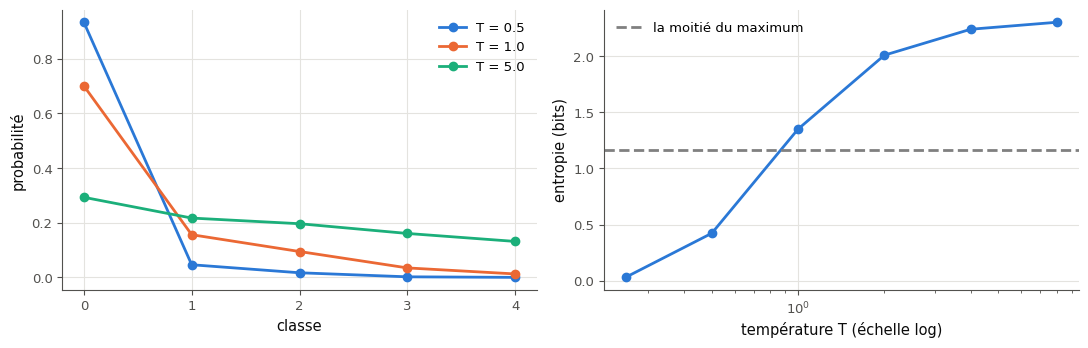

✅ Ex 17.19a : C'est ça !
✅ Ex 17.19b : Parfait !
✅ Ex 17.19c : Bravo !
✅ Ex 17.19d : Exact !


In [41]:
if any(answer is ... or answer is None for answer in [sharp_19, flat_19, half_19, negative_19]):
    print("⏳ Ex 17.19 : écris d'abord tes quatre prédictions, puis relance cette cellule.")
else:
    with wb.attempt("17.19"):
        A = mylearn.nn.activations
        table_19 = {T: np.asarray(A.softmax(SCORES_19 / T), dtype=float) for T in TEMPERATURES_19 + [5.0, -1.0]}
        entropy_19 = {T: float(-(p * np.log2(p)).sum()) for T, p in table_19.items()}
        for T in TEMPERATURES_19 + [5.0, -1.0]:
            print(f"T = {T:5.2f} : p = {np.round(table_19[T], 3).tolist()} · entropy {entropy_19[T]:.3f} bits "
                  f"(maximum log2(5) = {np.log2(5):.3f})")
        fig_19, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(11, 3.6))
        for T in [0.5, 1.0, 5.0]:
            ax_a.plot(range(5), table_19[T], "o-", label=f"T = {T}")
        ax_a.set_xticks(range(5))
        ax_a.set_xlabel("classe")
        ax_a.set_ylabel("probabilité")
        ax_a.legend()
        ax_b.plot(TEMPERATURES_19, [entropy_19[T] for T in TEMPERATURES_19], "o-")
        ax_b.axhline(np.log2(5) / 2, color="grey", ls="--", label="la moitié du maximum")
        ax_b.set_xscale("log")
        ax_b.set_xlabel("température T (échelle log)")
        ax_b.set_ylabel("entropie (bits)")
        ax_b.legend()
        plt.tight_layout()
        plt.show()
    wb.check("17.19a", sharp_19)
    wb.check("17.19b", flat_19)
    wb.check("17.19c", half_19)
    wb.check("17.19d", negative_19)

Dans tes notes : comment l'entropie évolue-t-elle quand $T$ grandit, et vers quelle valeur tend-elle ? Que fait une température négative à l'ordre des classes ? Un modèle de langage « créatif » utilise-t-il une petite ou une grande température ?

💡 À $T = 0{,}5$, la classe 0 prend 0,934 de la probabilité ; à $T = 5$, la moins probable garde 0,132 (l'uniforme donnerait 0,2). L'entropie croît avec $T$ : 0,03 bit à $T = 0{,}25$, 0,42 à $T = 0{,}5$, 1,35 à $T = 1$ (au-dessus de la moitié du maximum, 1,16), 2,30 à $T = 8$, et tend vers $\log_2 5$. Une température négative inverse les écarts, donc l'ordre : à $T = -1$, la classe 4, au plus petit score, prend 0,62. Un modèle de langage « créatif » utilise une température plus grande (proche de 1 ou au-dessus), un modèle « sûr » une petite température.

### Ex 17.20 — Quatre activations de scikit-learn sur les lunes et les spirales 📦 ★★ ⏱️ 25 min
**Objectif :** comparer, avec un protocole reproductible, les quatre activations de `MLPClassifier` sur deux problèmes.  
**Prérequis :** Ex 17.11 · ch. 15 (`MLPClassifier`) · fiche §17.6, section sur le choix d'une activation · **Fil rouge :** synthétique · **Parcours :** R, C

`MLPClassifier` propose quatre activations cachées : `"identity"`, `"logistic"` (la sigmoïde), `"tanh"` et `"relu"`. Compare-les sur deux problèmes : les deux lunes (600 points, bruit 0,25) et deux spirales (600 points, bruit 0,2, 1,5 tour), avec 30 % pour le test (`DATA_20`).

Écris `mean_accuracy_20(dataset, activation)` : pour `random_state` valant 0, 1, 2, 3 et 4, entraîne `MLPClassifier((16,), activation=activation, solver="lbfgs", max_iter=3000, random_state=random_state)` sur la partie d'entraînement de `DATA_20[dataset]` (avec `fit_quietly`), mesure son accuracy de test, et rends la **moyenne** des cinq accuracies (un `float`). La vérification calcule les huit moyennes avec ta fonction, affiche le tableau, et vérifie :
a) la moyenne de l'identité sur les spirales ;
b) `best_moons_20` : l'activation de meilleure moyenne sur les lunes (son nom, entre guillemets) ;
c) `best_spirals_20` : l'activation de meilleure moyenne sur les spirales ;
d) l'écart entre la moyenne de ReLU et celle de tanh sur les spirales (ReLU moins tanh).

Remplis b) et c) **après** avoir lu le tableau.

Dans tes notes : le classement est-il le même sur les deux problèmes ? Explique l'écart entre les activations sur les spirales (pense à la forme de la frontière que 16 neurones de chaque sorte peuvent tracer). Que dit l'écart entre les cinq graines (relance une ligne avec `np.std`) de la fiabilité d'une comparaison sur une seule graine ?

In [42]:
def split_20(X, y):
    return train_test_split(X, y, test_size=0.3, random_state=1720, stratify=y)


DATA_20 = {"lunes": split_20(*wb.synth.make_moons(n=600, noise=0.25, seed=1720)),
           "spirales": split_20(*wb.synth.make_spirals(n=600, noise=0.2, turns=1.5, seed=1720))}
ACTIVATIONS_20 = ["identity", "logistic", "tanh", "relu"]
for name, (Xtr, Xte, ytr, yte) in DATA_20.items():
    print(name, "train", Xtr.shape, "test", Xte.shape)

lunes train (420, 2) test (180, 2)
spirales train (420, 2) test (180, 2)


In [43]:
def mean_accuracy_20(dataset, activation):
    """Mean test accuracy over random_state = 0, 1, 2, 3, 4 of the protocol of the statement."""
    Xtr, Xte, ytr, yte = DATA_20[dataset]
    scores = []
    for seed in range(5):
        model = MLPClassifier((16,), activation=activation, solver="lbfgs", max_iter=3000, random_state=seed)
        scores.append(fit_quietly(model, Xtr, ytr).score(Xte, yte))
    return float(np.mean(scores))


best_moons_20, best_spirals_20 = "relu", "tanh"
results_20 = {}
if True:
    for dataset_20 in DATA_20:
        results_20[dataset_20] = {a: mean_accuracy_20(dataset_20, a) for a in ACTIVATIONS_20}
        print(f"{dataset_20:9s}", " · ".join(f"{a} {v:.3f}" for a, v in results_20[dataset_20].items()))
if len(results_20) == 2:
    print_answer("17.20a", results_20["spirales"]["identity"], computed=True)
    print_answer("17.20d", results_20["spirales"]["relu"] - results_20["spirales"]["tanh"], computed=True)
if True:
    print_answer("17.20b", best_moons_20)
    print_answer("17.20c", best_spirals_20)

lunes     identity 0.817 · logistic 0.898 · tanh 0.907 · relu 0.929


spirales  identity 0.639 · logistic 0.853 · tanh 0.992 · relu 0.837
17.20a: 0.6388888888888888
17.20d: -0.15555555555555556
17.20b: relu
17.20c: tanh


In [44]:
wb.record("17.20a", results_20["spirales"]["identity"], decimals=4,
          mistakes={"c'est la moyenne de l'identité sur les lunes ; relis la question : on demande les spirales": results_20["lunes"]["identity"]})
wb.record("17.20b", "relu", mistakes={"relis le tableau : sur les lunes, laquelle a la plus grande moyenne ?": "tanh",
                                      "la sigmoïde (logistic) n'est pas en tête sur les lunes": "logistic",
                                      "sans activation, le MLP trace une droite : il ne peut pas suivre les lunes": "identity"})
wb.record("17.20c", "tanh", mistakes={"relis le tableau : sur les spirales, laquelle a la plus grande moyenne ?": "relu",
                                      "la sigmoïde (logistic) n'est pas en tête sur les spirales": "logistic",
                                      "sans activation, le MLP trace une droite": "identity"})
wb.record("17.20d", results_20["spirales"]["relu"] - results_20["spirales"]["tanh"], decimals=4,
          mistakes={"ReLU moins tanh, pas l'inverse": results_20["spirales"]["tanh"] - results_20["spirales"]["relu"]})

WB_ANSWER {"decimals": 4, "hash": "d8d8d23f6fe88c9b29888e8ce9cd513fd45c99a16133f43273b177c899ca19b9", "hash_coarse": "e915082f444a2a697760223fd5a2ba24e81d7c14ce5fabdacd038af0d4f482bf", "id": "17.20a", "kind": "float", "magnitude": -1, "mistakes": {"dce07397e8e08478db51d70a68c044a6a2375f2d8c96957719289178f36439e3": "c'est la moyenne de l'identité sur les lunes ; relis la question : on demande les spirales"}, "sign": 1}
📝 Ex 17.20a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"hash": "7d8d815570d7c4f1654bf136c228c95c9902275e05df45cd4d1dcbf0dae49902", "id": "17.20b", "kind": "str", "mistakes": {"4b53e1d83e78c8cee46b25294aed25bbe83c54b74d51f851ccf84f457a2b4ada": "la sigmoïde (logistic) n'est pas en tête sur les lunes", "4f61c00320c64e06a2a093a405090df93a710928272ceb7c9ffb07f170a7edad": "relis le tableau : sur les lunes, laquelle a la plus grande moyenne ?", "946b260e2b1221010627ee7d9642594869bb1f20fcb19e224371e991e541961b": "sans activation, le MLP trace une droite : il ne peut

💡 Sur les lunes, ReLU est en tête (0,929), devant tanh (0,907) et la sigmoïde (0,898) ; l'identité, une droite, plafonne à 0,817. Sur les spirales, tanh domine nettement (0,992), la sigmoïde est très instable d'une graine à l'autre (0,853 en moyenne, avec un écart-type de 0,17), et ReLU ne fait que 0,837 : avec 16 neurones, une ReLU ne dispose que de 16 coudes pour approcher une spirale, alors que 16 courbes tanh s'additionnent en une frontière lisse. Le classement dépend donc du problème et de la taille du réseau : « ReLU par défaut » est un point de départ, pas une loi. L'écart-type entre graines (0,05 pour ReLU sur les spirales, 0,17 pour la sigmoïde) montre qu'une comparaison sur une seule graine peut s'inverser.

### Ex 17.21 — Diagnostiquer la saturation sur des histogrammes de pré-activations 📈 ★★ ⏱️ 20 min
**Objectif :** repérer sur des histogrammes les couches sigmoïdes saturées, puis le chiffrer avec ta dérivée.  
**Prérequis :** Ex 17.13 · ch. 16 (histogrammes d'activations) · fiche §17.6 (la saturation) · **Fil rouge :** synthétique · **Parcours :** M

La cellule ci-dessous trace les pré-activations $z$ de quatre couches sigmoïdes P, Q, R et S (1 000 exemples, 5 neurones chacune), comme le ferait un diagnostic avant l'entraînement (ch. 16). En rose : la zone $|z| > 4{,}6$, où $\sigma'(z) < 0{,}01$.

En lisant les histogrammes :
a) `most_21` : la lettre de la couche la plus saturée (celle dont les neurones ont, en moyenne, la plus petite pente) ;
b) `linear_21` : la lettre de la couche qui travaille presque dans la partie linéaire de la sigmoïde (une pente presque constante).

Puis écris `saturation_21(z)`, qui rend, avec **ta** `sigmoid_derivative`, la pente moyenne $\overline{\sigma'(z)}$ et la part des valeurs où $\sigma'(z) < 0{,}01$. La vérification calcule :
c) les pentes moyennes des quatre couches, dans l'ordre P, Q, R, S (une liste) ;
d) la part des pentes inférieures à 0,01 dans la couche R.

Dans tes notes : la couche R a-t-elle plus de valeurs dans la zone rose que Q ? Pourquoi sa pente moyenne est-elle pourtant plus grande ? Qu'est-ce qui, dans une initialisation ou dans les données, peut produire chacun des quatre histogrammes ?

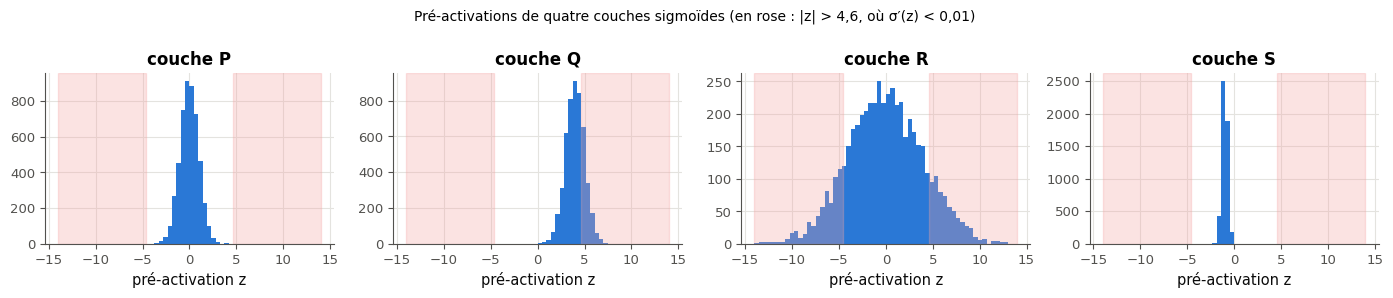

In [45]:
rng_21 = np.random.default_rng(1721)
SPECS_21 = {"P": (0.0, 1.0), "Q": (4.0, 1.0), "R": (0.0, 4.0), "S": (-1.0, 0.3)}       # mean, standard deviation
Z_21 = {name: rng_21.normal(m, s, size=(1000, 5)) for name, (m, s) in SPECS_21.items()}  # 1000 samples, 5 neurons
fig_21, axes_21 = plt.subplots(1, 4, figsize=(14, 3.0), sharex=True)
for ax, (name, z) in zip(axes_21, Z_21.items()):
    ax.hist(z.ravel(), bins=60, range=(-14, 14), color="#2a78d6")
    ax.axvspan(-14, -4.6, color="#f4a3a2", alpha=0.3)
    ax.axvspan(4.6, 14, color="#f4a3a2", alpha=0.3)
    ax.set_title(f"couche {name}")
    ax.set_xlabel("pré-activation z")
fig_21.suptitle("Pré-activations de quatre couches sigmoïdes (en rose : |z| > 4,6, où σ′(z) < 0,01)", fontsize=10)
plt.tight_layout()
plt.show()

In [46]:
most_21, linear_21 = "Q", "S"


def saturation_21(z):
    """(mean of sigmoid'(z), fraction of the values where sigmoid'(z) < 0.01), with YOUR sigmoid_derivative."""
    slope = np.asarray(mylearn.nn.activations.sigmoid_derivative(z), dtype=float)
    return float(slope.mean()), float(np.mean(slope < 0.01))
if True:
    print_answer("17.21a", most_21)
    print_answer("17.21b", linear_21)
if True:
    stats_21 = {name: saturation_21(z) for name, z in Z_21.items()}
    for name, (mean_slope, frac) in stats_21.items():
        print(f"couche {name} : pente moyenne {mean_slope:.4f} · part des pentes < 0,01 : {frac:.3f}")
    print_answer("17.21c", [stats_21[name][0] for name in "PQRS"], computed=True)
    print_answer("17.21d", stats_21["R"][1], computed=True)

17.21a: Q
17.21b: S
couche P : pente moyenne 0.2069 · part des pentes < 0,01 : 0.000
couche Q : pente moyenne 0.0268 · part des pentes < 0,01 : 0.278
couche R : pente moyenne 0.0909 · part des pentes < 0,01 : 0.252
couche S : pente moyenne 0.1952 · part des pentes < 0,01 : 0.000
17.21c: [0.2069, 0.0268, 0.0909, 0.1952]
17.21d: 0.2518


In [47]:
wb.record("17.21a", "Q", mistakes={"une distribution large a des valeurs loin de 0, mais plus de la moitié restent près de 0 : compare aussi les centres": "R",
                                    "cette couche est centrée en 0, avec un écart-type de 1 : sa pente reste forte": "P",
                                    "cette couche est étroite : ses pentes sont-elles petites ?": "S"})
wb.record("17.21b", "S", mistakes={"un écart-type de 1 couvre une bonne partie de la courbe en S, courbure comprise": "P",
                                   "cette couche est-elle dans la partie centrale de la courbe en S ?": "Q",
                                   "cette couche couvre toute la courbe, plateaux compris": "R"})
wb.record("17.21c", [stats_21[name][0] for name in "PQRS"], decimals=4)
wb.record("17.21d", stats_21["R"][1], decimals=4,
          mistakes={"c'est la part de la couche Q ; on demande la couche R": stats_21["Q"][1]})

WB_ANSWER {"hash": "d17e9e34133028ff6a9cd6c1c75919488b35c86790d11f945fa00407eb00c43a", "id": "17.21a", "kind": "str", "mistakes": {"5eb2a3e7760e2a4fe64b3480a7d76b3f61338bed50c4ce58fc33d318cd867425": "cette couche est centrée en 0, avec un écart-type de 1 : sa pente reste forte", "69ec90bb794392e96d8b6e5ce903a032744da603b0ed2adc34ea1751c80e0f78": "une distribution large a des valeurs loin de 0, mais plus de la moitié restent près de 0 : compare aussi les centres", "be477bce6c4441ff2a63669302eb9d4c32cd76bc9df85b7afe7a29c9ff6c6fda": "cette couche est étroite : ses pentes sont-elles petites ?"}}
📝 Ex 17.21a : réponse enregistrée (str).
WB_ANSWER {"hash": "15f4d219b959e2f19b607dd645af5d683dfc623c89f80f08282668922e5ad548", "id": "17.21b", "kind": "str", "mistakes": {"247b0c540bcca5d426ca4c9e7a1e554d25f34570ac73db9f5091c3b842c77916": "un écart-type de 1 couvre une bonne partie de la courbe en S, courbure comprise", "770e8bc0c67ad6568f747be882b572c91ea963a5391cd5161f52bc91169c54dd": "cette cou

💡 Q est centrée en 4 : presque tous ses $z$ sont sur le plateau du haut, et sa pente moyenne (0,027) est huit fois plus faible que celle de P (0,207). R, très large (écart-type 4), a presque autant de valeurs dans la zone rose (25 % contre 28 %), mais ses autres valeurs tombent souvent près de 0, où la pente est forte : sa pente moyenne (0,091) est plus de trois fois celle de Q. S, étroite autour de $-1$, est dans la partie presque linéaire (pente 0,195, presque constante). Q ressemble à une couche dont les biais sont trop grands (ou dont les entrées ne sont pas centrées) ; R à des poids trop grands ; S à des poids très petits et un biais négatif ; P à une bonne initialisation sur des entrées standardisées.

## Partie D · Tester et défier

Écrire une batterie de tests paramétrés pour toute une famille de fonctions (17.22), mesurer ce que chaque activation fait à un gradient qui traverse dix couches (17.23), puis relever le défi des spirales sous contrainte de paramètres (17.24).

### Ex 17.22 — Une batterie de tests paramétrés pour toutes les activations 🛠️ ★★ ⏱️ 25 min
**Objectif :** écrire des tests pytest paramétrés et des tests de propriétés qui attrapent cinq bugs différents dans une famille de fonctions.  
**Prérequis :** Ex 17.14 · 0A (`pytest.mark.parametrize`, `wb.run_pytest`) · fiche, section sur le choix et les tests · **Parcours :** C

La fonction `act_ok(name)` (fournie) rend le couple `(f, f′)` de quatre activations, `"relu"`, `"sigmoid"`, `"tanh"` et `"softplus"`, avec le contrat de ta librairie : chaque fonction rend un nouveau tableau `float64`, laisse son entrée intacte, reste finie sans avertissement pour $|z| \le 1\,000$, chaque dérivée vaut la pente de sa fonction, et $\mathrm{ReLU}'(0) = 0$ comme dans PyTorch. Écris une **batterie de tests** pytest pour une fonction `act(name)` qui a ce contrat : au moins un test doit être **paramétré** (`@pytest.mark.parametrize`, par exemple sur les quatre noms), et tu peux tester des **propriétés** (une fonction croissante, une dérivée égale à la pente numérique) plutôt que des valeurs.

Range tes tests dans la liste `my_tests_22`. Comme en 16.21, la vérification lance vraiment pytest : tes tests doivent **passer** sur `act_ok` et **échouer** sur chacune des cinq versions buggées fournies, `act_bug_1` à `act_bug_5` (lis-les : que fait chacune de travers ?). Tes tests ne peuvent utiliser que `act`, `np`, `math` et `pytest`. Cet exercice se corrige avec `05_solutions.md`.

Dans tes notes : pour chaque version buggée, le test qui l'attrape. Lesquelles passeraient un test qui compare les valeurs en trois points « ordinaires » comme $-1$, $0$ et $2$ ?

In [48]:
import math

import pytest                                     # for the @pytest.mark.parametrize decorators of your tests


def act_ok(name):
    """(f, f') for "relu", "sigmoid", "tanh" or "softplus": four activations and their derivatives (correct)."""
    def relu(z):
        z = np.array(z, dtype=float)
        return np.where(z > 0, z, 0.0)

    def relu_derivative(z):
        z = np.array(z, dtype=float)
        return (z > 0).astype(float)

    def sigmoid(z):
        z = np.array(z, dtype=float)
        e = np.exp(-np.abs(z))
        return np.where(z >= 0, 1 / (1 + e), e / (1 + e))

    def sigmoid_derivative(z):
        s = sigmoid(z)
        return s * (1 - s)

    def tanh(z):
        return np.tanh(np.array(z, dtype=float))

    def tanh_derivative(z):
        return 1 - np.tanh(np.array(z, dtype=float)) ** 2

    def softplus(z):
        z = np.array(z, dtype=float)
        return np.maximum(z, 0) + np.log1p(np.exp(-np.abs(z)))

    def softplus_derivative(z):
        return sigmoid(z)

    return {"relu": (relu, relu_derivative), "sigmoid": (sigmoid, sigmoid_derivative),
            "tanh": (tanh, tanh_derivative), "softplus": (softplus, softplus_derivative)}[name]


def act_bug_1(name):
    """(f, f') for "relu", "sigmoid", "tanh" or "softplus": the same, with one bug."""
    def relu(z):
        z = np.array(z, dtype=float)
        return np.where(z > 0, z, 0.0)

    def relu_derivative(z):
        z = np.array(z, dtype=float)
        return (z >= 0).astype(float)

    def sigmoid(z):
        z = np.array(z, dtype=float)
        e = np.exp(-np.abs(z))
        return np.where(z >= 0, 1 / (1 + e), e / (1 + e))

    def sigmoid_derivative(z):
        s = sigmoid(z)
        return s * (1 - s)

    def tanh(z):
        return np.tanh(np.array(z, dtype=float))

    def tanh_derivative(z):
        return 1 - np.tanh(np.array(z, dtype=float)) ** 2

    def softplus(z):
        z = np.array(z, dtype=float)
        return np.maximum(z, 0) + np.log1p(np.exp(-np.abs(z)))

    def softplus_derivative(z):
        return sigmoid(z)

    return {"relu": (relu, relu_derivative), "sigmoid": (sigmoid, sigmoid_derivative),
            "tanh": (tanh, tanh_derivative), "softplus": (softplus, softplus_derivative)}[name]


def act_bug_2(name):
    """(f, f') for "relu", "sigmoid", "tanh" or "softplus": the same, with one bug."""
    def relu(z):
        z = np.array(z, dtype=float)
        return np.where(z > 0, z, 0.0)

    def relu_derivative(z):
        z = np.array(z, dtype=float)
        return (z > 0).astype(float)

    def sigmoid(z):
        z = np.array(z, dtype=float)
        e = np.exp(-np.abs(z))
        return np.where(z >= 0, e / (1 + e), 1 / (1 + e))

    def sigmoid_derivative(z):
        s = sigmoid(z)
        return s * (1 - s)

    def tanh(z):
        return np.tanh(np.array(z, dtype=float))

    def tanh_derivative(z):
        return 1 - np.tanh(np.array(z, dtype=float)) ** 2

    def softplus(z):
        z = np.array(z, dtype=float)
        return np.maximum(z, 0) + np.log1p(np.exp(-np.abs(z)))

    def softplus_derivative(z):
        return sigmoid(z)

    return {"relu": (relu, relu_derivative), "sigmoid": (sigmoid, sigmoid_derivative),
            "tanh": (tanh, tanh_derivative), "softplus": (softplus, softplus_derivative)}[name]


def act_bug_3(name):
    """(f, f') for "relu", "sigmoid", "tanh" or "softplus": the same, with one bug."""
    def relu(z):
        z = np.array(z, dtype=float)
        return np.where(z > 0, z, 0.0)

    def relu_derivative(z):
        z = np.array(z, dtype=float)
        return (z > 0).astype(float)

    def sigmoid(z):
        z = np.array(z, dtype=float)
        e = np.exp(-np.abs(z))
        return np.where(z >= 0, 1 / (1 + e), e / (1 + e))

    def sigmoid_derivative(z):
        s = sigmoid(z)
        return s * (1 - s)

    def tanh(z):
        return np.tanh(np.array(z, dtype=float))

    def tanh_derivative(z):
        return 1 - np.tanh(np.tanh(np.array(z, dtype=float))) ** 2

    def softplus(z):
        z = np.array(z, dtype=float)
        return np.maximum(z, 0) + np.log1p(np.exp(-np.abs(z)))

    def softplus_derivative(z):
        return sigmoid(z)

    return {"relu": (relu, relu_derivative), "sigmoid": (sigmoid, sigmoid_derivative),
            "tanh": (tanh, tanh_derivative), "softplus": (softplus, softplus_derivative)}[name]


def act_bug_4(name):
    """(f, f') for "relu", "sigmoid", "tanh" or "softplus": the same, with one bug."""
    def relu(z):
        z = np.array(z, dtype=float)
        return np.where(z > 0, z, 0.0)

    def relu_derivative(z):
        z = np.array(z, dtype=float)
        return (z > 0).astype(float)

    def sigmoid(z):
        z = np.array(z, dtype=float)
        e = np.exp(-np.abs(z))
        return np.where(z >= 0, 1 / (1 + e), e / (1 + e))

    def sigmoid_derivative(z):
        s = sigmoid(z)
        return s * (1 - s)

    def tanh(z):
        return np.tanh(np.array(z, dtype=float))

    def tanh_derivative(z):
        return 1 - np.tanh(np.array(z, dtype=float)) ** 2

    def softplus(z):
        return np.log1p(np.exp(np.array(z, dtype=float)))

    def softplus_derivative(z):
        return sigmoid(z)

    return {"relu": (relu, relu_derivative), "sigmoid": (sigmoid, sigmoid_derivative),
            "tanh": (tanh, tanh_derivative), "softplus": (softplus, softplus_derivative)}[name]


def act_bug_5(name):
    """(f, f') for "relu", "sigmoid", "tanh" or "softplus": the same, with one bug."""
    def relu(z):
        z = np.array(z, dtype=float)
        return np.where(z > 0, z, 0.0)

    def relu_derivative(z):
        z = np.array(z, dtype=float)
        return (z > 0).astype(float)

    def sigmoid(z):
        z = np.array(z, dtype=float)
        e = np.exp(-np.abs(z))
        return np.where(z >= 0, 1 / (1 + e), e / (1 + e))

    def sigmoid_derivative(z):
        z = np.asarray(z, dtype=float)
        z *= -1.0                       # sigma'(-z) = sigma'(z): "saves" a copy
        s = sigmoid(z)
        return s * (1 - s)

    def tanh(z):
        return np.tanh(np.array(z, dtype=float))

    def tanh_derivative(z):
        return 1 - np.tanh(np.array(z, dtype=float)) ** 2

    def softplus(z):
        z = np.array(z, dtype=float)
        return np.maximum(z, 0) + np.log1p(np.exp(-np.abs(z)))

    def softplus_derivative(z):
        return sigmoid(z)

    return {"relu": (relu, relu_derivative), "sigmoid": (sigmoid, sigmoid_derivative),
            "tanh": (tanh, tanh_derivative), "softplus": (softplus, softplus_derivative)}[name]

In [49]:
@pytest.mark.parametrize("name", ["relu", "sigmoid", "tanh", "softplus"])
def test_derivative_matches_central_differences(name):
    f, df = act(name)
    z = np.linspace(-6, 6, 241)                                  # -6 to 6, step 0.05
    z = z[np.abs(z) > 1e-3]                                      # away from the kink of ReLU
    h = 1e-5
    assert np.allclose(df(z), (f(z + h) - f(z - h)) / (2 * h), rtol=1e-6, atol=1e-7)


@pytest.mark.parametrize("name", ["relu", "sigmoid", "tanh", "softplus"])
def test_function_is_non_decreasing(name):
    f, _ = act(name)
    assert np.all(np.diff(f(np.linspace(-6, 6, 241))) >= -1e-15)


@pytest.mark.parametrize("name", ["relu", "sigmoid", "tanh", "softplus"])
@pytest.mark.parametrize("which", [0, 1], ids=["f", "df"])
def test_large_inputs_stay_finite_without_warnings(name, which):
    g = act(name)[which]
    with np.errstate(over="raise", invalid="raise", divide="raise"):
        values = g(np.array([-1000.0, -50.0, 0.0, 50.0, 1000.0]))
    assert np.all(np.isfinite(values))


@pytest.mark.parametrize("name", ["relu", "sigmoid", "tanh", "softplus"])
@pytest.mark.parametrize("which", [0, 1], ids=["f", "df"])
def test_input_is_left_unchanged(name, which):
    z = np.array([-2.0, -0.5, 0.0, 1.5])
    before = z.copy()
    act(name)[which](z)
    assert np.array_equal(z, before)


def test_relu_derivative_is_zero_at_zero_as_in_pytorch():
    _, df = act("relu")
    assert df(np.array([0.0]))[0] == 0.0


my_tests_22 = [test_derivative_matches_central_differences, test_function_is_non_decreasing,
               test_large_inputs_stay_finite_without_warnings, test_input_is_left_unchanged,
               test_relu_derivative_is_zero_at_zero_as_in_pytorch]
def parametrized_22(tests):
    """True when at least one test function carries a pytest.mark.parametrize mark."""
    return any(mark.name == "parametrize" for t in tests for mark in getattr(t, "pytestmark", []))


if my_tests_22 is ...:
    print("⏳ Ex 17.22 : tests pas encore écrits.")
else:
    good_22 = wb.run_pytest(my_tests_22, subject=act_ok, name="act")
    verdict("17.22", parametrized_22(my_tests_22), "au moins un de tes tests est paramétré.",
            "aucun de tes tests n'est paramétré : utilise @pytest.mark.parametrize pour en exécuter un sur toute la famille.")
    verdict("17.22", good_22.ok, f"tes tests passent sur la version juste ({good_22.passed} cas).",
            "tes tests doivent tous passer sur act_ok, la version juste (voir le détail au-dessus).")
    if good_22.ok:
        for bug_22 in [act_bug_1, act_bug_2, act_bug_3, act_bug_4, act_bug_5]:
            result_22 = wb.run_pytest(my_tests_22, subject=bug_22, name="act", quiet=True)
            verdict("17.22", result_22.failed + result_22.errors > 0, f"{bug_22.__name__} est attrapé ({result_22.failed} cas en échec).",
                    f"tes tests passent sur {bug_22.__name__}, qui est faux : lis-le, puis ajoute un test qui le fait échouer.")

pytest : 25 passed in 0.28s
✅ Ex 17.22 : au moins un de tes tests est paramétré.
✅ Ex 17.22 : tes tests passent sur la version juste (25 cas).


✅ Ex 17.22 : act_bug_1 est attrapé (1 cas en échec).


✅ Ex 17.22 : act_bug_2 est attrapé (3 cas en échec).


✅ Ex 17.22 : act_bug_3 est attrapé (1 cas en échec).


✅ Ex 17.22 : act_bug_4 est attrapé (1 cas en échec).


✅ Ex 17.22 : act_bug_5 est attrapé (1 cas en échec).


💡 Une batterie de cinq tests suffit, dont quatre paramétrés : la pente numérique (attrape `act_bug_3`, la dérivée de tanh prise en sa sortie) ; une fonction croissante (attrape `act_bug_2`, qui rend $\sigma(-z)$ : ses valeurs restent dans $]0, 1[$ et vérifient même $\sigma(-z) = 1 - \sigma(z)$, seule la monotonie ou une comparaison à un oracle la trahit) ; des valeurs finies pour $\pm 1\,000$ (attrape `act_bug_4`, la softplus naïve, qui vaut `inf` en 1 000) ; une entrée intacte (attrape `act_bug_5`, qui retourne $z$ en place pour « économiser » une copie) ; et la convention en 0 (attrape `act_bug_1`, $\mathrm{ReLU}'(0) = 1$, que la pente numérique ne peut pas voir). En trois points ordinaires, `act_bug_1`, `act_bug_4` et `act_bug_5` passent (`act_bug_5` rend même les bonnes valeurs), et `act_bug_3` aussi si l'on ne teste que les fonctions.

### Ex 17.23 — Produit des dérivées sur 10 couches : sigmoïde, tanh, ReLU, GELU 🔬 ★★★ ⏱️ 45 min
**Objectif :** mesurer, couche par couche, les pentes des activations d'un réseau profond et ce qu'il reste d'un gradient après dix couches.  
**Prérequis :** Ex 17.14 · ch. 16 (initialisations de Glorot et He) · fiche §17.6 (la saturation) · **Fil rouge :** synthétique · **Parcours :** R, M, C

Un réseau de dix couches carrées de 64 neurones, sans biais, reçoit 500 exemples standardisés (`X_23`). Ses poids viennent de `weights_23(name)` : Glorot pour la sigmoïde et tanh, He pour ReLU et GELU, comme le recommande le ch. 16. Écris `slopes_23(name)` : la passe avant de `X_23` à travers ces dix couches ($\mathbf{z} = \mathbf{a}\mathbf{W}$, puis $\mathbf{a} = f(\mathbf{z})$), qui rend la liste des dix tableaux $f'(\mathbf{z})$, avec $f$ et $f'$ tirés de **ton** `get_activation`.

La vérification calcule, pour chaque activation, la pente moyenne de chaque couche, le **produit** de ces dix pentes moyennes, et le rapport entre la norme du gradient qui arrive sur l'entrée et celle du gradient parti de la dernière couche, calculé par `backward_ratio_23` avec la règle de la chaîne (le ch. 18 la détaillera : à chaque couche, le gradient est multiplié case par case par $f'(\mathbf{z})$, puis par $\mathbf{W}^\top$). Elle trace le produit cumulé des pentes moyennes, et contrôle trois ordres de grandeur.

Dans tes notes : pour quelle activation le gradient s'évanouit-il ? Pourquoi le produit des pentes moyennes de ReLU est-il si petit, alors que son gradient arrive presque intact ? Que se passerait-il avec ReLU et l'initialisation de Glorot (copie `weights_23` avec un paramètre `gain`, et refais l'expérience) ?

In [50]:
X_23 = np.random.default_rng(1723).normal(size=(500, 64))      # 500 standardized samples, 64 features
G_23 = np.random.default_rng(17231).normal(size=(500, 64))      # a gradient arriving on the last layer


def weights_23(name):
    """Ten square 64 x 64 layers, without bias: Glorot for sigmoid and tanh, He for relu and gelu (chapter 16)."""
    gain = 2.0 if name in ("relu", "gelu") else 1.0
    rng = np.random.default_rng(17230)
    return [rng.normal(0.0, np.sqrt(gain / 64), size=(64, 64)) for _ in range(10)]


def backward_ratio_23(Ws, slopes):
    """||gradient on the input|| / ||gradient on the last layer||, by the chain rule through the ten layers (ch. 18)."""
    g = G_23
    for W, s in zip(reversed(Ws), reversed(slopes)):
        g = (g * s) @ W.T
    return float(np.linalg.norm(g) / np.linalg.norm(G_23))

sigmoid  mean f' per layer [0.207, 0.232, 0.235, 0.236, 0.234, 0.236, 0.237, 0.235, 0.231, 0.236]
         product of the means 4.44e-07 · gradient ratio input/output 4.92e-07


tanh     mean f' per layer [0.607, 0.761, 0.826, 0.871, 0.901, 0.918, 0.925, 0.937, 0.94, 0.948]
         product of the means 2.12e-01 · gradient ratio input/output 2.71e-01


relu     mean f' per layer [0.507, 0.518, 0.495, 0.478, 0.546, 0.478, 0.499, 0.542, 0.448, 0.461]
         product of the means 9.06e-04 · gradient ratio input/output 9.58e-01


gelu     mean f' per layer [0.507, 0.521, 0.492, 0.48, 0.523, 0.477, 0.516, 0.516, 0.462, 0.498]
         product of the means 9.53e-04 · gradient ratio input/output 7.05e-01


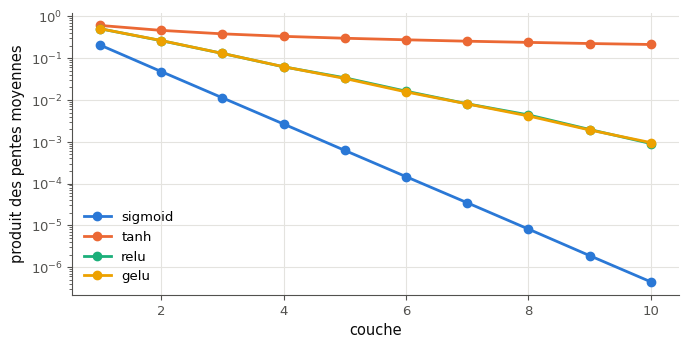

✅ Ex 17.23 : sigmoïde : le gradient est divisé par plus de 10⁴ (4.9e-07).
✅ Ex 17.23 : ReLU avec He : le gradient garde son ordre de grandeur (0.96).
✅ Ex 17.23 : ReLU : le produit des pentes moyennes s'effondre, mais pas le gradient : les poids de He compensent.


In [51]:
def slopes_23(name):
    """The ten arrays f'(z) (each of shape (500, 64)) of a forward pass of X_23 through weights_23(name),
    a = f(z) with z = a @ W at each layer, f and f' from YOUR get_activation(name)."""
    f, df = mylearn.nn.activations.get_activation(name)
    a, slopes = X_23, []
    for W in weights_23(name):
        z = a @ W
        slopes.append(np.asarray(df(z), dtype=float))
        a = np.asarray(f(z), dtype=float)
    return slopes
summary_23 = {}
if True:
    for name_23 in ["sigmoid", "tanh", "relu", "gelu"]:
        s_23 = slopes_23(name_23)
        if len(s_23) != 10 or any(np.shape(s) != (500, 64) for s in s_23):
            print(f"❌ Ex 17.23 : slopes_23({name_23!r}) doit rendre 10 tableaux de forme (500, 64).")
            continue
        means_23 = [float(np.mean(s)) for s in s_23]
        summary_23[name_23] = (means_23, float(np.prod(means_23)), backward_ratio_23(weights_23(name_23), s_23))
        print(f"{name_23:8s} mean f' per layer {np.round(means_23, 3).tolist()}")
        print(f"{'':8s} product of the means {summary_23[name_23][1]:.2e} · gradient ratio input/output {summary_23[name_23][2]:.2e}")
if len(summary_23) == 4:
    fig_23, ax_23 = plt.subplots(figsize=(7, 3.6))
    for name_23, (means_23, _, _) in summary_23.items():
        ax_23.plot(range(1, 11), np.cumprod(means_23), "o-", label=name_23)
    ax_23.set_yscale("log")
    ax_23.set_xlabel("couche")
    ax_23.set_ylabel("produit des pentes moyennes")
    ax_23.legend()
    plt.tight_layout()
    plt.show()
    verdict("17.23", summary_23["sigmoid"][2] < 1e-4, f"sigmoïde : le gradient est divisé par plus de 10⁴ ({summary_23['sigmoid'][2]:.1e}).",
            f"sigmoïde : un rapport de {summary_23['sigmoid'][2]:.1e} est inattendu ; vérifie tes dérivées (σ′ ≤ 1/4).")
    verdict("17.23", 0.1 < summary_23["relu"][2] < 10, f"ReLU avec He : le gradient garde son ordre de grandeur ({summary_23['relu'][2]:.2f}).",
            f"ReLU avec He : un rapport de {summary_23['relu'][2]:.2e} est inattendu ; vérifie relu_derivative.")
    verdict("17.23", summary_23["relu"][1] < 1e-2 < summary_23["relu"][2],
            "ReLU : le produit des pentes moyennes s'effondre, mais pas le gradient : les poids de He compensent.",
            "le produit des pentes de ReLU devrait être petit (≈ 0,5 par couche) et le rapport de gradients proche de 1.")

💡 La sigmoïde a des pentes moyennes de 0,21 à 0,24 à chaque couche (jamais plus de 1/4) : leur produit vaut $4 \times 10^{-7}$, et le gradient arrive sur l'entrée divisé par deux millions environ ($5 \times 10^{-7}$) : les premières couches n'apprendraient rien. tanh garde des pentes moyennes de 0,6 à 0,95 (ses activations restent près de 0, où sa pente vaut presque 1) : produit 0,21, gradient 0,27. ReLU a une pente moyenne d'environ 0,5 (la moitié des neurones sont actifs, de pente 1), soit un produit de $9 \times 10^{-4}$ ; mais l'initialisation de He double la variance des poids, et chaque $\mathbf{W}^\top$ compense ce facteur $1/2$ : le gradient arrive avec un rapport de 0,96. GELU, avec He, donne 0,7. Avec Glorot et ReLU, chaque couche diviserait la variance du gradient par 2 : un rapport de l'ordre de $2^{-5} \approx 0{,}03$ après dix couches. Le produit des pentes seul ne dit donc pas tout : c'est la combinaison de l'activation et de l'initialisation qui compte.

### Ex 17.24 — Défi spirales : au moins 97 % avec au plus 2 000 paramètres 🏆 ★★★ ⏱️ 60 min
**Objectif :** choisir activation, architecture, solveur et régularisation d'un MLP sous une contrainte de paramètres, et le vérifier sur des données jamais vues.  
**Prérequis :** Ex 17.20 · ch. 16 (compter les paramètres) · ch. 8 (validation croisée) · ch. 15 (`Pipeline`) · **Fil rouge :** synthétique · **Parcours :** C

Deux spirales entrelacées de 1 600 points (bruit 0,3, 2,5 tours) : la moitié pour l'entraînement (`X_24`, `y_24`), l'autre moitié forme un **test caché**. Écris `build_24()`, qui rend un modèle scikit-learn **neuf** (pas encore entraîné) : un `MLPClassifier`, éventuellement précédé d'un prétraitement dans un `Pipeline` (ch. 15). Tu choisis l'activation (parmi les quatre de scikit-learn), l'architecture, le solveur, la régularisation (`alpha`) et le nombre d'itérations.

Règles : au plus **2 000 paramètres** entraînés (poids et biais du `MLPClassifier`, comptés par `n_params_24`) ; le défi est réussi avec une accuracy d'au moins **0,97** sur le test caché **et** en moyenne sur quatre autres tirages des spirales (ta méthode est réentraînée sur chaque tirage) ; palier 🌟 : au moins 0,99 sur le test caché. La vérification entraîne ton modèle une dizaine de fois (validation croisée, test caché, quatre tirages) : garde un entraînement sous 5 secondes environ (`max_iter` de 1 000 à 3 000). Règle d'honneur : choisis tes réglages par validation croisée sur `X_24` seulement (la vérification l'affiche), et ne regarde le test caché qu'une fois : la vérification ne le révèle qu'une fois par session, et fige le résultat.

Dans tes notes : ta démarche (ce que tu as essayé, dans quel ordre, et les scores de validation croisée), puis ce qui a le plus compté : l'activation, la taille, `alpha` ou le solveur ? Le modèle par défaut, `MLPClassifier()`, qu'obtient-il en validation croisée ?

In [52]:
def spirals_24(seed):
    """Two spirals of 1600 points (noise 0.3, 2.5 turns), half for training and half for testing."""
    X, y = wb.synth.make_spirals(n=1600, n_classes=2, noise=0.3, turns=2.5, seed=seed)
    return train_test_split(X, y, test_size=0.5, random_state=seed, stratify=y)


X_24, X_HIDDEN_24, y_24, Y_HIDDEN_24 = spirals_24(1724)          # the test half is the hidden test: do not look at it
OTHER_SEEDS_24 = [2401, 2402, 2403, 2404]
print("training points:", X_24.shape, "· classes:", np.bincount(y_24).tolist())


def n_params_24(model):
    """The number of trained parameters of the MLPClassifier of a fitted model (or of the last step of a Pipeline)."""
    mlp = model[-1] if hasattr(model, "steps") else model
    return sum(W.size for W in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)

training points: (800, 2) · classes: [400, 400]


In [53]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def build_24():
    """A NEW, unfitted scikit-learn model: an MLPClassifier, or a Pipeline whose last step is an MLPClassifier."""
    return make_pipeline(StandardScaler(),
                         MLPClassifier((24, 24), activation="tanh", solver="lbfgs", alpha=0.1, max_iter=3000, random_state=0))
from sklearn.base import clone
from sklearn.exceptions import NotFittedError
from sklearn.model_selection import cross_val_score
from sklearn.utils.validation import check_is_fitted

if True:
    model_24 = build_24()
    last_24 = model_24[-1] if hasattr(model_24, "steps") else model_24
    rules_24 = isinstance(last_24, MLPClassifier)
    verdict("17.24", rules_24, "le modèle se termine par un MLPClassifier.",
            f"le dernier élément du modèle est un {type(last_24).__name__} : le défi demande un MLPClassifier.")
    try:
        check_is_fitted(model_24)
        rules_24 = False
        print("❌ Ex 17.24 : build_24 rend un modèle déjà entraîné : rends un modèle neuf.")
    except NotFittedError:
        pass
    if build_24() is model_24:
        rules_24 = False
        print("❌ Ex 17.24 : build_24 rend deux fois le même objet : crée un nouveau modèle à chaque appel.")
    if rules_24:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            cv_24 = cross_val_score(clone(model_24), X_24, y_24, cv=5)
        fitted_24 = fit_quietly(build_24(), X_24, y_24)
        params_24 = n_params_24(fitted_24)
        print(f"validation croisée sur l'entraînement : {cv_24.mean():.3f} ± {cv_24.std():.3f} · {params_24} paramètres")
        verdict("17.24", params_24 <= 2000, f"{params_24} paramètres, sous la limite de 2 000.",
                f"{params_24} paramètres : la limite est de 2 000 (poids et biais du MLPClassifier).")
        if params_24 <= 2000:
            if globals().get("REVEALED_24") is None:              # revealed once per session (an honour rule)
                others_24 = []
                for seed_24 in OTHER_SEEDS_24:
                    Xa, Xb, ya, yb = spirals_24(seed_24)
                    others_24.append(fit_quietly(build_24(), Xa, ya).score(Xb, yb))
                REVEALED_24 = (fitted_24.score(X_HIDDEN_24, Y_HIDDEN_24), float(np.mean(others_24)), params_24)
            test_24, mean_24, frozen_params_24 = REVEALED_24
            print(f"test caché : {test_24:.3f} · moyenne sur quatre autres tirages : {mean_24:.3f} "
                  f"(révélés une seule fois par session, pour le modèle à {frozen_params_24} paramètres)")
            verdict("17.24", test_24 >= 0.97 and mean_24 >= 0.97,
                    "défi réussi : au moins 0,97 sur le test caché et en moyenne sur quatre autres tirages."
                    + (" 🌟 Palier atteint : au moins 0,99 sur le test caché." if test_24 >= 0.99 else ""),
                    "pas encore : il faut au moins 0,97 sur le test caché ET en moyenne sur les quatre autres tirages.")

✅ Ex 17.24 : le modèle se termine par un MLPClassifier.


validation croisée sur l'entraînement : 0.985 ± 0.013 · 697 paramètres
✅ Ex 17.24 : 697 paramètres, sous la limite de 2 000.


test caché : 0.994 · moyenne sur quatre autres tirages : 0.996 (révélés une seule fois par session, pour le modèle à 697 paramètres)
✅ Ex 17.24 : défi réussi : au moins 0,97 sur le test caché et en moyenne sur quatre autres tirages. 🌟 Palier atteint : au moins 0,99 sur le test caché.


💡 Le modèle de référence, une standardisation suivie d'un MLP tanh 24-24 entraîné par `lbfgs` avec `alpha = 0.1` (697 paramètres), obtient 0,985 en validation croisée, 0,994 sur le test caché et 0,996 en moyenne sur les quatre autres tirages. Deux réglages comptent plus que l'activation : le **solveur** et la **régularisation**. Sans régularisation (`alpha` par défaut, $10^{-4}$), le même réseau colle aux 800 points d'entraînement (accuracy de 1) et tombe vers 0,95 en validation croisée ; avec `alpha` entre 0,01 et 0,1, il atteint 0,985. Et sans un solveur qui converge, rien ne marche : avec `adam` et 200 itérations, le `MLPClassifier()` par défaut (ReLU, 100 neurones) reste vers 0,60 en validation croisée, faute d'avoir convergé sur des entrées aussi petites (des rayons inférieurs à 1). Une ReLU 24-24 avec standardisation et `alpha = 0.1` fait presque aussi bien que tanh (0,991 en moyenne) ; sans standardisation (même `alpha`), elle est beaucoup moins stable (de 0,90 à 0,99 selon le tirage).

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu montrer qu'un réseau sans activation s'effondre, et calculer la couche qui le remplace ?
2. Sais-tu écrire chaque activation et sa dérivée sans débordement, et la softmax, la log-softmax et sa Jacobienne ?
3. Sais-tu choisir l'activation des couches cachées et celle de la sortie, et justifier ce choix par la saturation, les neurones morts et les gradients ?

**Pour aller plus loin** : les articles de Hendrycks et Gimpel (2016), de Ramachandran, Zoph et Le (2017) et de Shazeer (2020), cités dans la fiche. La suite : le ch. 18, où les couples `(f, f′)` de ton `get_activation` et le cache de ton `mlp_forward` serviront à la rétropropagation.